# ============================================================
# MIMIC-IV TIME-SERIES RISK CLASSIFICATION
# MODEL COMPARISON STUDY
#
# Models:
#   1. Bi-LSTM + Attention
#   2. GRU + Attention
#   3. 1D CNN
#
# Dataset:
#   MIMIC-IV Demo
#
# Input:
#   10 consecutive observations × 6 vital signs
#
# Output:
#   Stable / Moderate Risk / Critical Risk
# ============================================================

In [5]:
# ============================================================
# MIMIC-IV ICU RISK CLASSIFICATION
# MODEL COMPARISON STUDY
#
# Models:
# 1. Bi-LSTM + Attention
# 2. GRU + Attention
# 3. 1D CNN
#
# Dataset:
# MIMIC-IV Demo
#
# Classification:
# Stable / Moderate Risk / Critical Risk
# ============================================================


# ============================================================
# STEP 1: IMPORT LIBRARIES
# ============================================================

import os
import time
import copy
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn

from torch.utils.data import (
    TensorDataset,
    DataLoader
)

from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split

from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")


In [6]:
# ============================================================
# STEP 2: REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

print("=" * 70)
print("REPRODUCIBILITY")
print("=" * 70)

print("Random seed:", SEED)

REPRODUCIBILITY
Random seed: 42


In [7]:
# ============================================================
# STEP 3: DEVICE / GPU INFORMATION
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\n" + "=" * 70)
print("HARDWARE CONFIGURATION")
print("=" * 70)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CUDA version:", torch.version.cuda)
print("Selected device:", device)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

    print(
        "GPU Memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / (1024 ** 3),
            2
        ),
        "GB"
    )

else:

    print("GPU: Not available")




HARDWARE CONFIGURATION
PyTorch version: 2.14.1+cpu
CUDA available: False
CUDA version: None
Selected device: cpu
GPU: Not available


In [8]:
# ============================================================
# STEP 4: CONFIGURATION
# ============================================================

# ------------------------------------------------------------
# CHANGE THIS PATH
# ------------------------------------------------------------

ICU_PATH = r"YOUR_PATH_TO_MIMIC_IV_DEMO\icu"


# Features that will be used

FEATURES = [
    "heart_rate",
    "spo2",
    "respiratory_rate",
    "sbp",
    "dbp",
    "temperature"
]


# Model configuration

SEQUENCE_LENGTH = 10

INPUT_SIZE = 6

HIDDEN_SIZE = 64

NUM_LAYERS = 2

NUM_CLASSES = 3

DROPOUT = 0.3

BATCH_SIZE = 64

LEARNING_RATE = 0.001

WEIGHT_DECAY = 1e-5

MAX_EPOCHS = 30

PATIENCE = 5


CLASS_NAMES = [
    "Stable",
    "Moderate Risk",
    "Critical Risk"
]


print("\n" + "=" * 70)
print("EXPERIMENT CONFIGURATION")
print("=" * 70)

print("Sequence length:", SEQUENCE_LENGTH)
print("Number of features:", INPUT_SIZE)
print("Hidden size:", HIDDEN_SIZE)
print("Number of classes:", NUM_CLASSES)
print("Dropout:", DROPOUT)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Maximum epochs:", MAX_EPOCHS)
print("Early stopping patience:", PATIENCE)

print("\nFeatures:")
for feature in FEATURES:
    print(" -", feature)






EXPERIMENT CONFIGURATION
Sequence length: 10
Number of features: 6
Hidden size: 64
Number of classes: 3
Dropout: 0.3
Batch size: 64
Learning rate: 0.001
Weight decay: 1e-05
Maximum epochs: 30
Early stopping patience: 5

Features:
 - heart_rate
 - spo2
 - respiratory_rate
 - sbp
 - dbp
 - temperature


In [9]:
import os

ICU_PATH = os.getcwd()

ITEMS_PATH = os.path.join(
    ICU_PATH,
    "d_items.csv.gz"
)

CHARTEVENTS_PATH = os.path.join(
    ICU_PATH,
    "chartevents.csv.gz"
)

In [10]:
# ============================================================
# STEP 5: CHECK DATASET FILES
# ============================================================

print("\n" + "=" * 70)
print("DATASET FILE CHECK")
print("=" * 70)

print("D_ITEMS file:")
print("Exists:", os.path.exists(ITEMS_PATH))

print("CHARTEVENTS file:")
print("Exists:", os.path.exists(CHARTEVENTS_PATH))

if not os.path.exists(ITEMS_PATH):
    raise FileNotFoundError(
        f"\nd_items.csv.gz not found at:\n{ITEMS_PATH}"
    )

if not os.path.exists(CHARTEVENTS_PATH):
    raise FileNotFoundError(
        f"\nchartevents.csv.gz not found at:\n{CHARTEVENTS_PATH}"
    )

print("\nBoth dataset files found successfully!")


DATASET FILE CHECK
D_ITEMS file:
Exists: True
CHARTEVENTS file:
Exists: True

Both dataset files found successfully!


In [11]:
# ============================================================
# STEP 6: LOAD d_items
# ============================================================

print("\n" + "=" * 70)
print("STEP 6: LOADING ITEM DICTIONARY")
print("=" * 70)



items = pd.read_csv(
    ITEMS_PATH,
    compression="gzip"
)

print("\nd_items loaded successfully!")

print("Shape:", items.shape)

print("\nColumns:")
print(items.columns.tolist())

print("\nFirst 5 rows:")
display(items.head())


STEP 6: LOADING ITEM DICTIONARY

d_items loaded successfully!
Shape: (4014, 9)

Columns:
['itemid', 'label', 'abbreviation', 'linksto', 'category', 'unitname', 'param_type', 'lownormalvalue', 'highnormalvalue']

First 5 rows:


,itemid,label,abbreviation,linksto,category,unitname,param_type,lownormalvalue,highnormalvalue
0,226228,Gender,Gender,chartevents,ADT,NaN,Text,NaN,NaN
1,226545,Race,Race,chartevents,ADT,NaN,Text,NaN,NaN
2,229877,Suction events (CH),Suction events (CH),chartevents,ECMO,NaN,Text,NaN,NaN
3,229875,Oxygenator visible (CH),Oxygenator visible (CH),chartevents,ECMO,NaN,Text,NaN,NaN
4,229266,Cannula sites visually inspected (ECMO),Cannula sites visually inspected (ECMO),chartevents,ECMO,NaN,Text,NaN,NaN


In [12]:
# ============================================================
# STEP 7: IDENTIFY VITAL-SIGN ITEM IDS
# ============================================================

print("\n" + "=" * 70)
print("STEP 7: IDENTIFYING VITAL-SIGN ITEM IDS")
print("=" * 70)


# Search terms used to identify the required measurements

search_terms = {

    "heart_rate": "Heart Rate",

    "spo2": "O2 saturation",

    "respiratory_rate": "Respiratory Rate",

    "sbp": "Systolic Blood Pressure",

    "dbp": "Diastolic Blood Pressure",

    "temperature": "Temperature"
}


VITAL_ITEMS = {}


for feature, search_text in search_terms.items():

    match = items[
        items["label"]
        .astype(str)
        .str.contains(
            search_text,
            case=False,
            na=False
        )
    ]

    print("\nSearching for:", feature)

    print("Possible matches:", len(match))

    if len(match) > 0:

        display(
            match[
                [
                    "itemid",
                    "label",
                    "category",
                    "unitname"
                ]
            ].head(10)
        )


# ------------------------------------------------------------
# Use the known MIMIC-IV item IDs from the original pipeline
# ------------------------------------------------------------

VITAL_ITEMS = {

    "heart_rate": 220045,

    "spo2": 220277,

    "respiratory_rate": 220210,

    "sbp": 220179,

    "dbp": 220180,

    "temperature": 223762
}


print("\nAutomatically selected vital-sign item IDs:\n")

for feature, itemid in VITAL_ITEMS.items():

    print(
        f"{feature:20s} -> itemid {itemid}"
    )



STEP 7: IDENTIFYING VITAL-SIGN ITEM IDS

Searching for: heart_rate
Possible matches: 3


,itemid,label,category,unitname
2054,220047,Heart Rate Alarm - Low,Alarms,bpm
2063,220046,Heart rate Alarm - High,Alarms,bpm
2577,220045,Heart Rate,Routine Vital Signs,bpm



Searching for: spo2
Possible matches: 9


,itemid,label,category,unitname
1976,220227,Arterial O2 Saturation,Labs,%
2067,223770,O2 Saturation Pulseoxymetry Alarm - Low,Alarms,%
2069,223769,O2 Saturation Pulseoxymetry Alarm - High,Alarms,%
2327,220277,O2 saturation pulseoxymetry,Respiratory,%
2447,226862,PA %O2 Saturation (PA Line),PA Line Insertion,%
2449,226863,PVR %O2 Saturation (PA Line),PA Line Insertion,dynes*sec/cm5
2451,226861,ART %O2 saturation (PA Line),PA Line Insertion,%
2458,226865,SVR %O2 Saturation (PA Line),PA Line Insertion,dynes*sec/cm5
2463,226860,RA %O2 Saturation (PA Line),PA Line Insertion,%



Searching for: respiratory_rate
Possible matches: 4


,itemid,label,category,unitname
2284,224688,Respiratory Rate (Set),Respiratory,insp/min
2314,224690,Respiratory Rate (Total),Respiratory,insp/min
2329,220210,Respiratory Rate,Respiratory,insp/min
2344,224689,Respiratory Rate (spontaneous),Respiratory,insp/min



Searching for: sbp
Possible matches: 0

Searching for: dbp
Possible matches: 0

Searching for: temperature
Possible matches: 9


,itemid,label,category,unitname
415,224674,Changes in Temperature,Toxicology,NaN
1177,224027,Skin Temperature,Skin - Assessment,NaN
1564,224642,Temperature Site,Routine Vital Signs,NaN
1957,228242,Pt. Temperature (BG) (SOFT),Labs,NaN
2397,229236,Cerebral Temperature (C),Hemodynamics,°C
2570,223761,Temperature Fahrenheit,Routine Vital Signs,°F
2573,223762,Temperature Celsius,Routine Vital Signs,°C
2578,226329,Blood Temperature CCO (C),Routine Vital Signs,°C
2633,227054,TemperatureF_ApacheIV,Scores - APACHE IV (2),°F



Automatically selected vital-sign item IDs:

heart_rate           -> itemid 220045
spo2                 -> itemid 220277
respiratory_rate     -> itemid 220210
sbp                  -> itemid 220179
dbp                  -> itemid 220180
temperature          -> itemid 223762


In [13]:
# ============================================================
# STEP 8: LOAD CHARTEVENTS
# ============================================================

print("\n" + "=" * 70)
print("STEP 8: EXTRACTING VITAL-SIGN DATA")
print("=" * 70)

chartevents_path = CHARTEVENTS_PATH


if not os.path.exists(chartevents_path):
    raise FileNotFoundError(
        "chartevents.csv.gz was not found."
    )

selected_itemids = list(
    VITAL_ITEMS.values()
)

vital_chunks = []

print("\nReading chartevents in chunks...")

chunk_number = 0

for chunk in pd.read_csv(
    chartevents_path,
    compression="gzip",
    usecols=[
        "subject_id",
        "stay_id",
        "charttime",
        "itemid",
        "valuenum"
    ],
    chunksize=100000
):

    chunk_number += 1

    filtered = chunk[
        chunk["itemid"].isin(selected_itemids)
    ].copy()

    if not filtered.empty:
        vital_chunks.append(filtered)

    if chunk_number % 10 == 0:
        print(
            "Processed chunks:",
            chunk_number
        )

vitals_raw = pd.concat(
    vital_chunks,
    ignore_index=True
)

print("\nExtraction complete!")

print(
    "Rows extracted:",
    len(vitals_raw)
)

print(
    "Patients:",
    vitals_raw["subject_id"].nunique()
)

print(
    "ICU stays:",
    vitals_raw["stay_id"].nunique()
)


STEP 8: EXTRACTING VITAL-SIGN DATA

Reading chartevents in chunks...

Extraction complete!
Rows extracted: 58453
Patients: 100
ICU stays: 140


In [14]:
# ============================================================
# STEP 9: INSPECT RAW EXTRACTED DATA
# ============================================================

print("\n" + "=" * 70)
print("STEP 9: RAW DATA INSPECTION")
print("=" * 70)


item_to_feature = {

    itemid: feature

    for feature, itemid
    in VITAL_ITEMS.items()

}


vitals_raw["feature"] = (
    vitals_raw["itemid"]
    .map(item_to_feature)
)


print("\nFirst 10 extracted observations:")

display(
    vitals_raw.head(10)
)


print("\nObservations per feature:")

display(
    vitals_raw["feature"]
    .value_counts()
)


print("\nMissing values in raw extracted data:")

display(
    vitals_raw.isnull().sum()
)



STEP 9: RAW DATA INSPECTION

First 10 extracted observations:


,subject_id,stay_id,charttime,itemid,valuenum,feature
0,10005817,32604416,2132-12-16 00:00:00,220210,19.0,respiratory_rate
1,10005817,32604416,2132-12-16 00:00:00,223762,37.0,temperature
2,10005817,32604416,2132-12-16 00:00:00,220045,80.0,heart_rate
3,10005817,32604416,2132-12-16 00:00:00,220277,95.0,spo2
4,10005817,32604416,2132-12-16 01:00:00,220045,82.0,heart_rate
5,10005817,32604416,2132-12-16 01:00:00,223762,37.0,temperature
6,10005817,32604416,2132-12-16 01:00:00,220277,96.0,spo2
7,10005817,32604416,2132-12-16 01:00:00,220210,18.0,respiratory_rate
8,10005817,32604416,2132-12-16 02:00:00,220277,95.0,spo2
9,10005817,32604416,2132-12-16 02:00:00,223762,37.1,temperature



Observations per feature:


feature
respiratory_rate    13913
heart_rate          13913
spo2                13540
dbp                  8349
sbp                  8347
temperature           391
Name: count, dtype: int64


Missing values in raw extracted data:


subject_id    0
stay_id       0
charttime     0
itemid        0
valuenum      0
feature       0
dtype: int64

In [15]:
# ============================================================
# STEP 10: TIME-SERIES PIVOT
# ============================================================

print("\n" + "=" * 70)
print("STEP 10: CONVERTING TO TIME-SERIES FORMAT")
print("=" * 70)

vitals_raw["charttime"] = pd.to_datetime(
    vitals_raw["charttime"]
)

time_series = (
    vitals_raw
    .pivot_table(
        index=[
            "subject_id",
            "stay_id",
            "charttime"
        ],
        columns="feature",
        values="valuenum",
        aggfunc="mean"
    )
    .reset_index()
)

# Remove the "feature" column-axis name
time_series.columns.name = None

print("\nPivot completed!")

print(
    "Time-series shape:",
    time_series.shape
)

print("\nTime-series columns:")
print(time_series.columns.tolist())

print("\nFirst 5 rows:")
display(time_series.head())


STEP 10: CONVERTING TO TIME-SERIES FORMAT

Pivot completed!
Time-series shape: (19411, 9)

Time-series columns:
['subject_id', 'stay_id', 'charttime', 'dbp', 'heart_rate', 'respiratory_rate', 'sbp', 'spo2', 'temperature']

First 5 rows:


,subject_id,stay_id,charttime,dbp,heart_rate,respiratory_rate,sbp,spo2,temperature
0,10000032,39553978,2180-07-23 14:11:00,48.0,NaN,NaN,84.0,NaN,NaN
1,10000032,39553978,2180-07-23 14:12:00,NaN,91.0,24.0,NaN,NaN,NaN
2,10000032,39553978,2180-07-23 14:13:00,NaN,NaN,NaN,NaN,98.0,NaN
3,10000032,39553978,2180-07-23 14:30:00,59.0,93.0,21.0,95.0,97.0,NaN
4,10000032,39553978,2180-07-23 15:00:00,56.0,94.0,23.0,88.0,97.0,NaN


In [16]:

# ============================================================
# STEP 11: SORT CHRONOLOGICALLY
# ============================================================

print("\n" + "=" * 70)
print("STEP 11: SORTING TIME-SERIES")
print("=" * 70)


time_series = (

    time_series

    .sort_values(
        [
            "subject_id",
            "stay_id",
            "charttime"
        ]
    )

    .reset_index(drop=True)

)


print("Chronological sorting completed.")

print("\nFirst 10 rows:")

display(
    time_series.head(10)
)




STEP 11: SORTING TIME-SERIES
Chronological sorting completed.

First 10 rows:


,subject_id,stay_id,charttime,dbp,heart_rate,respiratory_rate,sbp,spo2,temperature
0,10000032,39553978,2180-07-23 14:11:00,48.0,NaN,NaN,84.0,NaN,NaN
1,10000032,39553978,2180-07-23 14:12:00,NaN,91.0,24.0,NaN,NaN,NaN
2,10000032,39553978,2180-07-23 14:13:00,NaN,NaN,NaN,NaN,98.0,NaN
3,10000032,39553978,2180-07-23 14:30:00,59.0,93.0,21.0,95.0,97.0,NaN
4,10000032,39553978,2180-07-23 15:00:00,56.0,94.0,23.0,88.0,97.0,NaN
5,10000032,39553978,2180-07-23 16:00:00,NaN,105.0,21.0,NaN,94.0,NaN
6,10000032,39553978,2180-07-23 16:01:00,55.0,NaN,NaN,91.0,NaN,NaN
7,10000032,39553978,2180-07-23 17:00:00,58.0,97.0,20.0,95.0,95.0,NaN
8,10000032,39553978,2180-07-23 18:00:00,53.0,100.0,21.0,86.0,95.0,NaN
9,10000032,39553978,2180-07-23 19:00:00,41.0,97.0,16.0,93.0,98.0,NaN


In [17]:
# ============================================================
# STEP 12: CHECK MISSING VALUES BEFORE INTERPOLATION
# ============================================================

print("\n" + "=" * 70)
print("STEP 12: MISSING VALUES BEFORE INTERPOLATION")
print("=" * 70)


print(
    time_series[FEATURES]
    .isnull()
    .sum()
)


print("\nMissing-value percentages:")

missing_percentage = (
    time_series[FEATURES]
    .isnull()
    .mean()
    * 100
)

display(
    missing_percentage
)



STEP 12: MISSING VALUES BEFORE INTERPOLATION
heart_rate           5498
spo2                 5871
respiratory_rate     5498
sbp                 11064
dbp                 11062
temperature         19020
dtype: int64

Missing-value percentages:


heart_rate          28.324146
spo2                30.245737
respiratory_rate    28.324146
sbp                 56.998609
dbp                 56.988306
temperature         97.985678
dtype: float64

In [18]:
# ============================================================
# STEP 13: INTERPOLATE MISSING VALUES
# ============================================================

print("\n" + "=" * 70)
print("STEP 13: INTERPOLATING MISSING VALUES")
print("=" * 70)


# ------------------------------------------------------------
# Interpolate separately within each ICU stay
# ------------------------------------------------------------

for feature in FEATURES:

    # Linear interpolation within each patient + ICU stay
    time_series[feature] = (
        time_series
        .groupby(
            ["subject_id", "stay_id"]
        )[feature]
        .transform(
            lambda s: s.interpolate(
                method="linear",
                limit_direction="both"
            )
        )
    )


# ------------------------------------------------------------
# Fill any remaining missing values
# using the median of each ICU stay
# ------------------------------------------------------------

for feature in FEATURES:

    stay_median = (
        time_series
        .groupby(
            ["subject_id", "stay_id"]
        )[feature]
        .transform("median")
    )

    time_series[feature] = (
        time_series[feature]
        .fillna(stay_median)
    )


# ------------------------------------------------------------
# Final fallback: global median
# ------------------------------------------------------------

for feature in FEATURES:

    time_series[feature] = (
        time_series[feature]
        .fillna(
            time_series[feature].median()
        )
    )


# ------------------------------------------------------------
# Sort again after interpolation
# ------------------------------------------------------------

time_series = (
    time_series
    .sort_values(
        [
            "subject_id",
            "stay_id",
            "charttime"
        ]
    )
    .reset_index(drop=True)
)


print("\nMissing value handling complete!")

print("\nTime-series columns:")
print(time_series.columns.tolist())

print("\nTime-series shape:")
print(time_series.shape)

print("\nRemaining missing values:")

display(
    time_series[FEATURES]
    .isnull()
    .sum()
)

print("\nFirst 5 rows:")
display(time_series.head())


STEP 13: INTERPOLATING MISSING VALUES



Missing value handling complete!

Time-series columns:
['subject_id', 'stay_id', 'charttime', 'dbp', 'heart_rate', 'respiratory_rate', 'sbp', 'spo2', 'temperature']

Time-series shape:
(19411, 9)

Remaining missing values:


heart_rate          0
spo2                0
respiratory_rate    0
sbp                 0
dbp                 0
temperature         0
dtype: int64


First 5 rows:


,subject_id,stay_id,charttime,dbp,heart_rate,respiratory_rate,sbp,spo2,temperature
0,10000032,39553978,2180-07-23 14:11:00,48.000000,91.0,24.0,84.000000,98.0,36.9
1,10000032,39553978,2180-07-23 14:12:00,51.666667,91.0,24.0,87.666667,98.0,36.9
2,10000032,39553978,2180-07-23 14:13:00,55.333333,92.0,22.5,91.333333,98.0,36.9
3,10000032,39553978,2180-07-23 14:30:00,59.000000,93.0,21.0,95.000000,97.0,36.9
4,10000032,39553978,2180-07-23 15:00:00,56.000000,94.0,23.0,88.000000,97.0,36.9


In [19]:
# ============================================================
# STEP 14: CREATE PHYSIOLOGICAL RISK SCORE
# ============================================================

print("\n" + "=" * 70)
print("STEP 14: CREATE PHYSIOLOGICAL RISK LABELS")
print("=" * 70)


time_series["risk_score"] = 0


# ------------------------------------------------------------
# Heart rate
# ------------------------------------------------------------

time_series.loc[

    (
        (time_series["heart_rate"] < 50)
        |
        (time_series["heart_rate"] > 120)
    ),

    "risk_score"

] += 1


# ------------------------------------------------------------
# SpO2
# ------------------------------------------------------------

time_series.loc[

    time_series["spo2"] < 92,

    "risk_score"

] += 1


# ------------------------------------------------------------
# Respiratory rate
# ------------------------------------------------------------

time_series.loc[

    (
        (time_series["respiratory_rate"] < 10)
        |
        (time_series["respiratory_rate"] > 30)
    ),

    "risk_score"

] += 1


# ------------------------------------------------------------
# Systolic blood pressure
# ------------------------------------------------------------

time_series.loc[

    (
        (time_series["sbp"] < 90)
        |
        (time_series["sbp"] > 180)
    ),

    "risk_score"

] += 1


# ------------------------------------------------------------
# Diastolic blood pressure
# ------------------------------------------------------------

time_series.loc[

    (
        (time_series["dbp"] < 60)
        |
        (time_series["dbp"] > 110)
    ),

    "risk_score"

] += 1


# ------------------------------------------------------------
# Temperature
# ------------------------------------------------------------

time_series.loc[

    (
        (time_series["temperature"] < 36)
        |
        (time_series["temperature"] > 38)
    ),

    "risk_score"

] += 1

print("\nRisk score distribution:")
print(time_series["risk_score"].value_counts().sort_index())

print("\nMaximum risk score:")
print(time_series["risk_score"].max())


STEP 14: CREATE PHYSIOLOGICAL RISK LABELS

Risk score distribution:
risk_score
0    8475
1    7617
2    2670
3     579
4      61
5       9
Name: count, dtype: int64

Maximum risk score:
5


In [20]:
# ============================================================
# STEP 15: CONVERT RISK SCORE TO CLASS
# ============================================================


def assign_risk(score):

    if score == 0:

        return 0

    elif score <= 2:

        return 1

    else:

        return 2


time_series["risk_label"] = (

    time_series["risk_score"]

    .apply(assign_risk)

)


print("\nRisk labels created!")


print("\nRisk score distribution:")

display(
    time_series["risk_score"]
    .value_counts()
    .sort_index()
)


print("\nRisk class distribution:")

display(
    time_series["risk_label"]
    .value_counts()
    .sort_index()
)


print("\nClass labels:")

print("0 = Stable")
print("1 = Moderate Risk")
print("2 = Critical Risk")


print("\nSample labelled data:")

display(

    time_series[
        FEATURES
        +
        [
            "risk_score",
            "risk_label"
        ]
    ]

    .head(10)

)


Risk labels created!

Risk score distribution:


risk_score
0    8475
1    7617
2    2670
3     579
4      61
5       9
Name: count, dtype: int64


Risk class distribution:


risk_label
0     8475
1    10287
2      649
Name: count, dtype: int64


Class labels:
0 = Stable
1 = Moderate Risk
2 = Critical Risk

Sample labelled data:


,heart_rate,spo2,respiratory_rate,sbp,dbp,temperature,risk_score,risk_label
0,91.0,98.0,24.0,84.000000,48.000000,36.9,2,1
1,91.0,98.0,24.0,87.666667,51.666667,36.9,2,1
2,92.0,98.0,22.5,91.333333,55.333333,36.9,1,1
3,93.0,97.0,21.0,95.000000,59.000000,36.9,1,1
4,94.0,97.0,23.0,88.000000,56.000000,36.9,2,1
5,105.0,94.0,21.0,89.500000,55.500000,36.9,2,1
6,101.0,94.5,20.5,91.000000,55.000000,36.9,1,1
7,97.0,95.0,20.0,95.000000,58.000000,36.9,1,1
8,100.0,95.0,21.0,86.000000,53.000000,36.9,2,1
9,97.0,98.0,16.0,93.000000,41.000000,36.9,1,1



STEP 16: RISK CLASS DISTRIBUTION


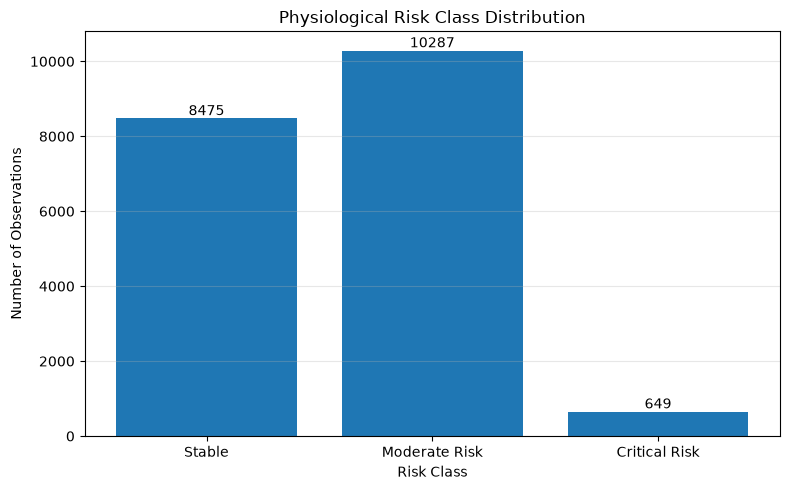

In [21]:
# ============================================================
# STEP 16: RISK CLASS DISTRIBUTION GRAPH
# ============================================================

print("\n" + "=" * 70)
print("STEP 16: RISK CLASS DISTRIBUTION")
print("=" * 70)


class_counts = (

    time_series["risk_label"]

    .value_counts()

    .sort_index()

)


plt.figure(
    figsize=(8, 5)
)


bars = plt.bar(

    [
        "Stable",
        "Moderate Risk",
        "Critical Risk"
    ],

    class_counts.values

)


plt.xlabel("Risk Class")

plt.ylabel("Number of Observations")

plt.title(
    "Physiological Risk Class Distribution"
)

plt.grid(
    axis="y",
    alpha=0.3
)


for bar, value in zip(
    bars,
    class_counts.values
):

    plt.text(

        bar.get_x()
        + bar.get_width() / 2,

        bar.get_height(),

        str(value),

        ha="center",

        va="bottom"

    )


plt.tight_layout()

plt.show()




STEP 17: VITAL-SIGN DISTRIBUTIONS


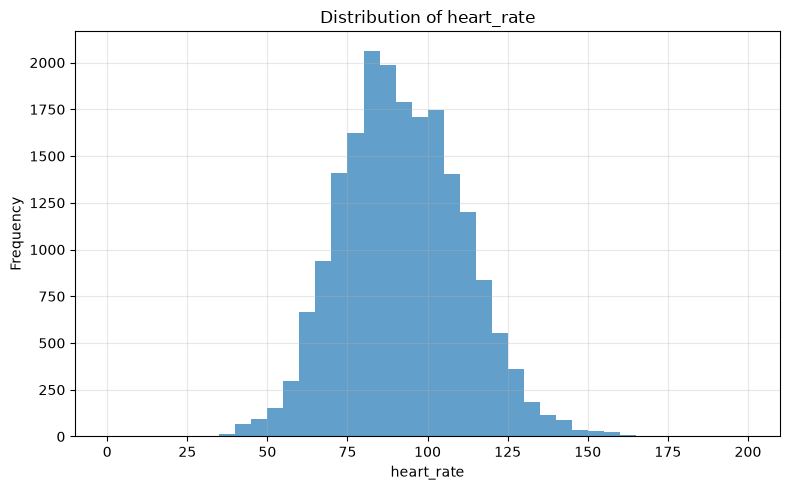

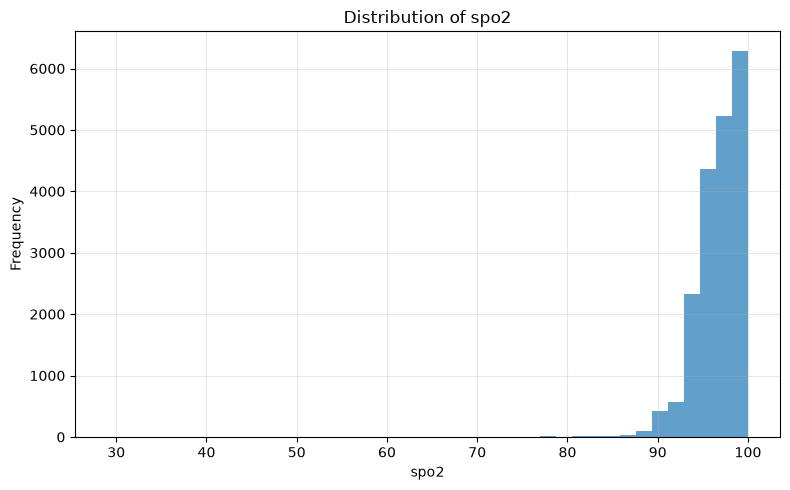

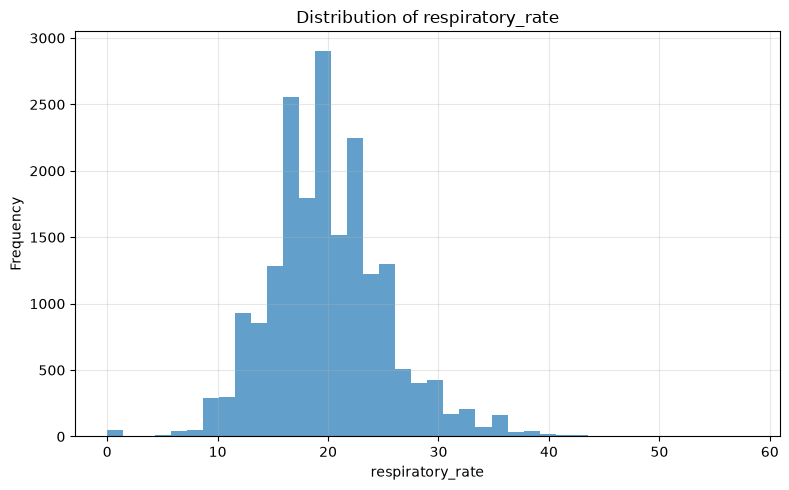

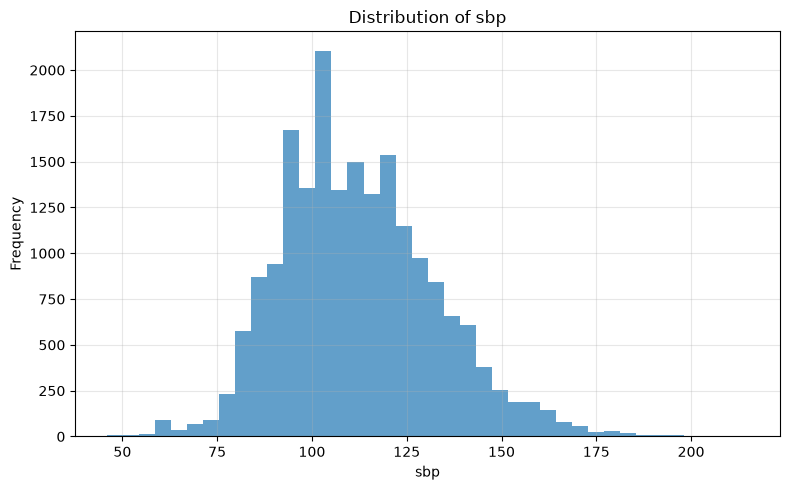

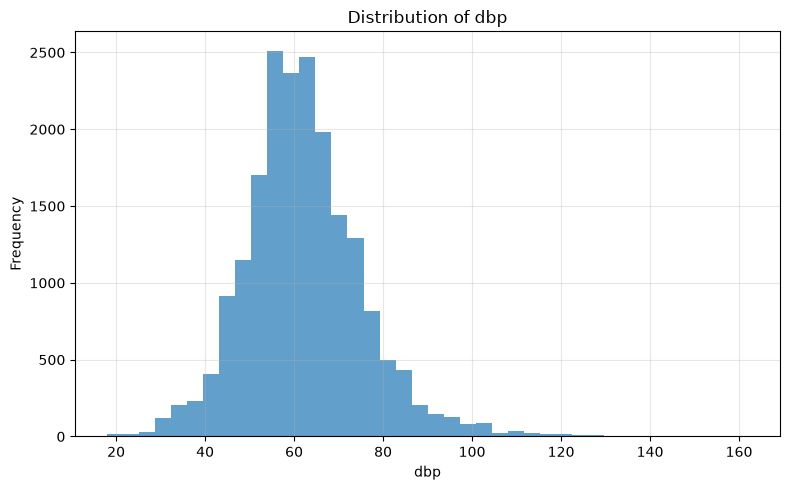

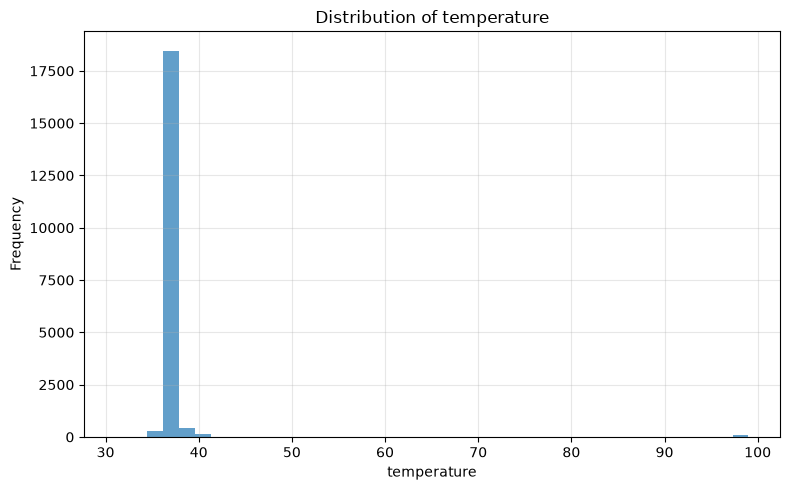

In [22]:
# ============================================================
# STEP 17: VITAL-SIGN DISTRIBUTIONS
# ============================================================

print("\n" + "=" * 70)
print("STEP 17: VITAL-SIGN DISTRIBUTIONS")
print("=" * 70)


for feature in FEATURES:

    plt.figure(
        figsize=(8, 5)
    )

    plt.hist(

        time_series[feature],

        bins=40,

        alpha=0.7

    )

    plt.xlabel(feature)

    plt.ylabel("Frequency")

    plt.title(
        f"Distribution of {feature}"
    )

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


In [23]:
print("time_series columns:")
print(time_series.columns.tolist())

print("\nFirst 5 rows:")
display(time_series.head())

time_series columns:
['subject_id', 'stay_id', 'charttime', 'dbp', 'heart_rate', 'respiratory_rate', 'sbp', 'spo2', 'temperature', 'risk_score', 'risk_label']

First 5 rows:


,subject_id,stay_id,charttime,dbp,heart_rate,respiratory_rate,sbp,spo2,temperature,risk_score,risk_label
0,10000032,39553978,2180-07-23 14:11:00,48.000000,91.0,24.0,84.000000,98.0,36.9,2,1
1,10000032,39553978,2180-07-23 14:12:00,51.666667,91.0,24.0,87.666667,98.0,36.9,2,1
2,10000032,39553978,2180-07-23 14:13:00,55.333333,92.0,22.5,91.333333,98.0,36.9,1,1
3,10000032,39553978,2180-07-23 14:30:00,59.000000,93.0,21.0,95.000000,97.0,36.9,1,1
4,10000032,39553978,2180-07-23 15:00:00,56.000000,94.0,23.0,88.000000,97.0,36.9,2,1


In [24]:
# ============================================================
# STEP 18: CREATE SEQUENCES
# ============================================================

print("\n" + "=" * 70)
print("STEP 18: CREATING TIME-SERIES SEQUENCES")
print("=" * 70)

X = []
y = []

sequence_subject_ids = []
sequence_stay_ids = []

# ------------------------------------------------------------
# Create sequences separately for each ICU stay
# ------------------------------------------------------------

for (subject_id, stay_id), group in time_series.groupby(
    ["subject_id", "stay_id"]
):

    # Sort observations chronologically
    group = group.sort_values("charttime")

    # Extract six vital-sign features
    values = group[FEATURES].values

    # Extract corresponding risk labels
    labels = group["risk_label"].values

    # Skip ICU stays with fewer than 10 observations
    if len(group) < SEQUENCE_LENGTH:
        continue

    # --------------------------------------------------------
    # Sliding window
    # --------------------------------------------------------

    for i in range(
        len(group) - SEQUENCE_LENGTH + 1
    ):

        # 10 consecutive timesteps × 6 features
        X.append(
            values[
                i:i + SEQUENCE_LENGTH
            ]
        )

        # Label = risk at the final timestep
        y.append(
            labels[
                i + SEQUENCE_LENGTH - 1
            ]
        )

        # Store patient and ICU-stay ID
        sequence_subject_ids.append(subject_id)
        sequence_stay_ids.append(stay_id)


# ------------------------------------------------------------
# Convert lists to NumPy arrays
# ------------------------------------------------------------

X = np.array(X)
y = np.array(y)

sequence_subject_ids = np.array(
    sequence_subject_ids
)

sequence_stay_ids = np.array(
    sequence_stay_ids
)


# ============================================================
# CHECK RESULTS
# ============================================================

print("\nSequence creation complete!")

print("\nX shape:")
print(X.shape)

print("\ny shape:")
print(y.shape)

print("\nExpected format:")
print(
    "X = [number of sequences, 10 timesteps, 6 features]"
)

print(
    "\nNumber of sequences:",
    len(X)
)

print(
    "Timesteps per sequence:",
    X.shape[1]
)

print(
    "Features per timestep:",
    X.shape[2]
)

print("\nRisk label distribution:")

display(
    pd.Series(y)
    .value_counts()
    .sort_index()
)


STEP 18: CREATING TIME-SERIES SEQUENCES

Sequence creation complete!

X shape:
(18167, 10, 6)

y shape:
(18167,)

Expected format:
X = [number of sequences, 10 timesteps, 6 features]

Number of sequences: 18167
Timesteps per sequence: 10
Features per timestep: 6

Risk label distribution:


0    7860
1    9693
2     614
Name: count, dtype: int64

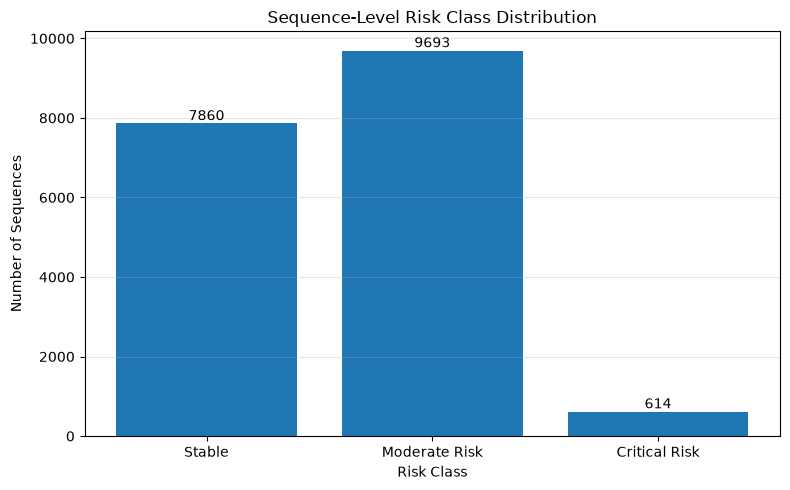

In [25]:
# ============================================================
# STEP 19: SEQUENCE LABEL DISTRIBUTION GRAPH
# ============================================================

plt.figure(
    figsize=(8, 5)
)


sequence_counts = (

    pd.Series(y)

    .value_counts()

    .sort_index()

)


bars = plt.bar(

    CLASS_NAMES,

    sequence_counts.values

)


plt.xlabel("Risk Class")

plt.ylabel("Number of Sequences")

plt.title(
    "Sequence-Level Risk Class Distribution"
)

plt.grid(
    axis="y",
    alpha=0.3
)


for bar, value in zip(
    bars,
    sequence_counts.values
):

    plt.text(

        bar.get_x()
        + bar.get_width() / 2,

        bar.get_height(),

        str(value),

        ha="center",

        va="bottom"

    )


plt.tight_layout()

plt.show()


In [26]:
# ============================================================
# STEP 20: PATIENT-WISE TRAIN / VALIDATION / TEST SPLIT
# ============================================================

print("\n" + "=" * 70)
print("STEP 20: PATIENT-WISE TRAIN / VALIDATION / TEST SPLIT")
print("=" * 70)


unique_subjects = np.unique(
    sequence_subject_ids
)


print(
    "Total unique patients:",
    len(unique_subjects)
)


# 70% training
# 15% validation
# 15% testing

train_subjects, temp_subjects = (

    train_test_split(

        unique_subjects,

        test_size=0.30,

        random_state=SEED

    )

)


val_subjects, test_subjects = (

    train_test_split(

        temp_subjects,

        test_size=0.50,

        random_state=SEED

    )

)


train_mask = np.isin(

    sequence_subject_ids,

    train_subjects

)


val_mask = np.isin(

    sequence_subject_ids,

    val_subjects

)


test_mask = np.isin(

    sequence_subject_ids,

    test_subjects

)


X_train = X[train_mask]

y_train = y[train_mask]


X_val = X[val_mask]

y_val = y[val_mask]


X_test = X[test_mask]

y_test = y[test_mask]


print("\nPatient-wise split complete!")


print("\nTraining:")

print(
    "X_train:",
    X_train.shape
)

print(
    "y_train:",
    y_train.shape
)


print("\nValidation:")

print(
    "X_val:",
    X_val.shape
)

print(
    "y_val:",
    y_val.shape
)


print("\nTesting:")

print(
    "X_test:",
    X_test.shape
)

print(
    "y_test:",
    y_test.shape
)


print("\nPatients:")

print(
    "Training patients:",
    len(train_subjects)
)

print(
    "Validation patients:",
    len(val_subjects)
)

print(
    "Testing patients:",
    len(test_subjects)
)



STEP 20: PATIENT-WISE TRAIN / VALIDATION / TEST SPLIT
Total unique patients: 100

Patient-wise split complete!

Training:
X_train: (12671, 10, 6)
y_train: (12671,)

Validation:
X_val: (2941, 10, 6)
y_val: (2941,)

Testing:
X_test: (2555, 10, 6)
y_test: (2555,)

Patients:
Training patients: 70
Validation patients: 15
Testing patients: 15


In [27]:
# ============================================================
# STEP 21: VERIFY PATIENT SEPARATION
# ============================================================

print("\n" + "=" * 70)
print("STEP 21: VERIFYING NO PATIENT OVERLAP")
print("=" * 70)


train_set = set(train_subjects)

val_set = set(val_subjects)

test_set = set(test_subjects)


print(
    "Train ∩ Validation:",
    len(train_set & val_set)
)

print(
    "Train ∩ Test:",
    len(train_set & test_set)
)

print(
    "Validation ∩ Test:",
    len(val_set & test_set)
)


STEP 21: VERIFYING NO PATIENT OVERLAP
Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


In [28]:
# ============================================================
# STEP 22: CLASS DISTRIBUTION AFTER SPLIT
# ============================================================

print("\n" + "=" * 70)
print("STEP 22: CLASS DISTRIBUTION AFTER SPLIT")
print("=" * 70)


print("\nTraining class distribution:")

display(
    pd.Series(y_train)
    .value_counts()
    .sort_index()
)


print("\nValidation class distribution:")

display(
    pd.Series(y_val)
    .value_counts()
    .sort_index()
)


print("\nTest class distribution:")

display(
    pd.Series(y_test)
    .value_counts()
    .sort_index()
)


STEP 22: CLASS DISTRIBUTION AFTER SPLIT

Training class distribution:


0    5170
1    7037
2     464
Name: count, dtype: int64


Validation class distribution:


0    1810
1    1037
2      94
Name: count, dtype: int64


Test class distribution:


0     880
1    1619
2      56
Name: count, dtype: int64

In [29]:
# ============================================================
# STEP 23: FEATURE SCALING
# ============================================================

print("\n" + "=" * 70)
print("STEP 23: FEATURE SCALING")
print("=" * 70)


scaler = StandardScaler()


# Flatten training data

X_train_flat = X_train.reshape(
    -1,
    INPUT_SIZE
)


X_val_flat = X_val.reshape(
    -1,
    INPUT_SIZE
)


X_test_flat = X_test.reshape(
    -1,
    INPUT_SIZE
)


# Fit ONLY on training data

scaler.fit(
    X_train_flat
)


X_train = scaler.transform(
    X_train_flat
).reshape(
    X_train.shape
)


X_val = scaler.transform(
    X_val_flat
).reshape(
    X_val.shape
)


X_test = scaler.transform(
    X_test_flat
).reshape(
    X_test.shape
)


print("StandardScaler fitted using training data only.")

print("\nScaled training shape:")

print(X_train.shape)


print("\nScaled validation shape:")

print(X_val.shape)


print("\nScaled testing shape:")

print(X_test.shape)


print("\nTraining feature means after scaling:")

print(
    X_train.reshape(
        -1,
        INPUT_SIZE
    ).mean(axis=0)
)


print("\nTraining feature standard deviations:")

print(
    X_train.reshape(
        -1,
        INPUT_SIZE
    ).std(axis=0)
)



STEP 23: FEATURE SCALING


StandardScaler fitted using training data only.

Scaled training shape:
(12671, 10, 6)

Scaled validation shape:
(2941, 10, 6)

Scaled testing shape:
(2555, 10, 6)

Training feature means after scaling:
[-1.29794140e-14  3.54183418e-14  8.23109853e-15 -1.78253636e-14
  6.79124239e-15  3.32147246e-12]

Training feature standard deviations:
[1. 1. 1. 1. 1. 1.]


In [59]:
# ============================================================
# SAVE PHASE 1 SCALER
# ============================================================

import os
import joblib

os.makedirs("model", exist_ok=True)

joblib.dump(
    scaler,
    "model/phase1_scaler.pkl"
)

print("Scaler saved successfully!")
print("Path: model/phase1_scaler.pkl")

Scaler saved successfully!
Path: model/phase1_scaler.pkl


In [61]:
# ============================================================
# STEP 24: CLASS WEIGHTS
# ============================================================

print("\n" + "=" * 70)
print("STEP 24: CALCULATING CLASS WEIGHTS")
print("=" * 70)


classes = np.unique(
    y_train
)


class_weights_np = compute_class_weight(

    class_weight="balanced",

    classes=classes,

    y=y_train

)


class_weights = torch.tensor(

    class_weights_np,

    dtype=torch.float32

).to(device)


print("Classes:")

print(classes)


print("\nClass weights:")

print(class_weights)



STEP 24: CALCULATING CLASS WEIGHTS
Classes:
[0 1 2]

Class weights:
tensor([0.8170, 0.6002, 9.1027])


In [31]:
# ============================================================
# STEP 25: CREATE PYTORCH DATASETS
# ============================================================

print("\n" + "=" * 70)
print("STEP 25: CREATING PYTORCH DATASETS")
print("=" * 70)


X_train_tensor = torch.tensor(
    X_train,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train,
    dtype=torch.long
)


X_val_tensor = torch.tensor(
    X_val,
    dtype=torch.float32
)

y_val_tensor = torch.tensor(
    y_val,
    dtype=torch.long
)


X_test_tensor = torch.tensor(
    X_test,
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test,
    dtype=torch.long
)


train_dataset = TensorDataset(

    X_train_tensor,

    y_train_tensor

)


val_dataset = TensorDataset(

    X_val_tensor,

    y_val_tensor

)


test_dataset = TensorDataset(

    X_test_tensor,

    y_test_tensor

)



STEP 25: CREATING PYTORCH DATASETS


In [32]:
# ============================================================
# STEP 26: CREATE DATALOADERS
# ============================================================

print("\n" + "=" * 70)
print("STEP 26: CREATING DATALOADERS")
print("=" * 70)


train_loader = DataLoader(

    train_dataset,

    batch_size=BATCH_SIZE,

    shuffle=True,

    pin_memory=torch.cuda.is_available()

)


val_loader = DataLoader(

    val_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    pin_memory=torch.cuda.is_available()

)


test_loader = DataLoader(

    test_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    pin_memory=torch.cuda.is_available()

)


print("DataLoaders created successfully!")

print("\nBatch size:", BATCH_SIZE)

print(
    "Training batches:",
    len(train_loader)
)

print(
    "Validation batches:",
    len(val_loader)
)

print(
    "Testing batches:",
    len(test_loader)
)



STEP 26: CREATING DATALOADERS
DataLoaders created successfully!

Batch size: 64
Training batches: 198
Validation batches: 46
Testing batches: 40


In [33]:
# ============================================================
# STEP 27: ATTENTION LAYER
# ============================================================

print("\n" + "=" * 70)
print("STEP 27: DEFINING ATTENTION LAYER")
print("=" * 70)


class AttentionLayer(nn.Module):

    def __init__(
        self,
        hidden_dim
    ):

        super().__init__()


        self.attention = nn.Sequential(

            nn.Linear(
                hidden_dim,
                64
            ),

            nn.Tanh(),

            nn.Linear(
                64,
                1
            )

        )


    def forward(
        self,
        sequence_output
    ):

        attention_scores = (

            self.attention(
                sequence_output
            )

            .squeeze(-1)

        )


        attention_weights = torch.softmax(

            attention_scores,

            dim=1

        )


        attention_weights_expanded = (

            attention_weights
            .unsqueeze(-1)

        )


        context_vector = torch.sum(

            sequence_output
            *
            attention_weights_expanded,

            dim=1

        )


        return (
            context_vector,
            attention_weights
        )


print("Attention layer created successfully!")



STEP 27: DEFINING ATTENTION LAYER
Attention layer created successfully!


In [34]:
# ============================================================
# STEP 28: Bi-LSTM + ATTENTION
# ============================================================

print("\n" + "=" * 70)
print("STEP 28: DEFINING Bi-LSTM + ATTENTION")
print("=" * 70)


class BiLSTMAttention(nn.Module):

    def __init__(

        self,

        input_size=6,

        hidden_size=64,

        num_layers=2,

        num_classes=3,

        dropout=0.3

    ):

        super().__init__()


        self.lstm = nn.LSTM(

            input_size=input_size,

            hidden_size=hidden_size,

            num_layers=num_layers,

            batch_first=True,

            bidirectional=True,

            dropout=(
                dropout
                if num_layers > 1
                else 0
            )

        )


        lstm_output_dim = (
            hidden_size * 2
        )


        self.attention = AttentionLayer(

            lstm_output_dim

        )


        self.classifier = nn.Sequential(

            nn.Linear(
                lstm_output_dim,
                64
            ),

            nn.ReLU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                64,
                num_classes
            )

        )


    def forward(

        self,

        x,

        return_attention=False

    ):

        lstm_output, _ = self.lstm(x)


        context_vector, attention_weights = (

            self.attention(
                lstm_output
            )

        )


        logits = self.classifier(
            context_vector
        )


        if return_attention:

            return (
                logits,
                attention_weights
            )


        return logits



STEP 28: DEFINING Bi-LSTM + ATTENTION


In [35]:
# ============================================================
# STEP 29: GRU + ATTENTION
# ============================================================

print("\n" + "=" * 70)
print("STEP 29: DEFINING GRU + ATTENTION")
print("=" * 70)


class GRUAttention(nn.Module):

    def __init__(

        self,

        input_size=6,

        hidden_size=64,

        num_layers=2,

        num_classes=3,

        dropout=0.3

    ):

        super().__init__()


        self.gru = nn.GRU(

            input_size=input_size,

            hidden_size=hidden_size,

            num_layers=num_layers,

            batch_first=True,

            dropout=(
                dropout
                if num_layers > 1
                else 0
            )

        )


        self.attention = AttentionLayer(

            hidden_size

        )


        self.classifier = nn.Sequential(

            nn.Linear(
                hidden_size,
                64
            ),

            nn.ReLU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                64,
                num_classes
            )

        )


    def forward(

        self,

        x,

        return_attention=False

    ):

        gru_output, _ = self.gru(x)


        context_vector, attention_weights = (

            self.attention(
                gru_output
            )

        )


        logits = self.classifier(
            context_vector
        )


        if return_attention:

            return (
                logits,
                attention_weights
            )


        return logits



STEP 29: DEFINING GRU + ATTENTION


In [36]:
# ============================================================
# STEP 30: 1D CNN
# ============================================================

print("\n" + "=" * 70)
print("STEP 30: DEFINING 1D CNN")
print("=" * 70)


class CNN1DClassifier(nn.Module):

    def __init__(

        self,

        input_size=6,

        num_classes=3,

        dropout=0.3

    ):

        super().__init__()


        # Input:
        # batch x timesteps x features
        #
        # Conv1D expects:
        # batch x channels x timesteps


        self.conv = nn.Sequential(

            nn.Conv1d(

                in_channels=input_size,

                out_channels=64,

                kernel_size=3,

                padding=1

            ),

            nn.BatchNorm1d(64),

            nn.ReLU(),

            nn.Conv1d(

                in_channels=64,

                out_channels=128,

                kernel_size=3,

                padding=1

            ),

            nn.BatchNorm1d(128),

            nn.ReLU(),

            nn.AdaptiveAvgPool1d(1)

        )


        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(
                128,
                64
            ),

            nn.ReLU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                64,
                num_classes
            )

        )


    def forward(self, x):

        # x:
        # batch x timesteps x features

        x = x.transpose(
            1,
            2
        )

        x = self.conv(x)

        x = self.classifier(x)

        return x



STEP 30: DEFINING 1D CNN


In [37]:
# ============================================================
# STEP 31: MODEL PARAMETER FUNCTION
# ============================================================

def count_parameters(model):

    return sum(

        p.numel()

        for p in model.parameters()

        if p.requires_grad

    )


In [38]:
# ============================================================
# STEP 32: CREATE MODELS
# ============================================================

print("\n" + "=" * 70)
print("STEP 32: INITIALIZING MODELS")
print("=" * 70)


models = {

    "Bi-LSTM + Attention":
        BiLSTMAttention(
            input_size=INPUT_SIZE,
            hidden_size=HIDDEN_SIZE,
            num_layers=NUM_LAYERS,
            num_classes=NUM_CLASSES,
            dropout=DROPOUT
        ).to(device),


    "GRU + Attention":
        GRUAttention(
            input_size=INPUT_SIZE,
            hidden_size=HIDDEN_SIZE,
            num_layers=NUM_LAYERS,
            num_classes=NUM_CLASSES,
            dropout=DROPOUT
        ).to(device),


    "1D CNN":
        CNN1DClassifier(
            input_size=INPUT_SIZE,
            num_classes=NUM_CLASSES,
            dropout=DROPOUT
        ).to(device)

}


for model_name, model in models.items():

    print("\n" + "-" * 70)

    print(model_name)

    print("-" * 70)

    print(model)

    print(
        "\nTrainable parameters:",
        f"{count_parameters(model):,}"
    )


STEP 32: INITIALIZING MODELS

----------------------------------------------------------------------
Bi-LSTM + Attention
----------------------------------------------------------------------
BiLSTMAttention(
  (lstm): LSTM(6, 64, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (attention): AttentionLayer(
    (attention): Sequential(
      (0): Linear(in_features=128, out_features=64, bias=True)
      (1): Tanh()
      (2): Linear(in_features=64, out_features=1, bias=True)
    )
  )
  (classifier): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=3, bias=True)
  )
)

Trainable parameters: 152,964

----------------------------------------------------------------------
GRU + Attention
----------------------------------------------------------------------
GRUAttention(
  (gru): GRU(6, 64, num_layers=2, batch_first=True, dropout=0.3)
  (attention)

In [39]:
# ============================================================
# STEP 33: LOSS FUNCTION
# ============================================================

criterion = nn.CrossEntropyLoss(

    weight=class_weights

)


print("\n" + "=" * 70)
print("LOSS FUNCTION")
print("=" * 70)

print(criterion)



LOSS FUNCTION
CrossEntropyLoss()


In [40]:
# ============================================================
# STEP 34: TRAINING FUNCTION
# ============================================================

def train_one_epoch(

    model,

    loader,

    criterion,

    optimizer

):

    model.train()


    running_loss = 0.0

    correct = 0

    total = 0


    for X_batch, y_batch in loader:

        X_batch = X_batch.to(
            device,
            non_blocking=True
        )

        y_batch = y_batch.to(
            device,
            non_blocking=True
        )


        optimizer.zero_grad()


        outputs = model(
            X_batch
        )


        loss = criterion(

            outputs,

            y_batch

        )


        loss.backward()


        optimizer.step()


        running_loss += (

            loss.item()
            *
            X_batch.size(0)

        )


        predictions = torch.argmax(

            outputs,

            dim=1

        )


        correct += (

            predictions == y_batch

        ).sum().item()


        total += y_batch.size(0)


    epoch_loss = (
        running_loss / total
    )


    epoch_accuracy = (
        correct / total
    )


    return (
        epoch_loss,
        epoch_accuracy
    )

In [41]:
# ============================================================
# STEP 35: EVALUATION FUNCTION
# ============================================================

def evaluate_model(

    model,

    loader,

    criterion

):

    model.eval()


    running_loss = 0.0

    correct = 0

    total = 0


    all_predictions = []

    all_labels = []


    with torch.no_grad():

        for X_batch, y_batch in loader:

            X_batch = X_batch.to(
                device,
                non_blocking=True
            )

            y_batch = y_batch.to(
                device,
                non_blocking=True
            )


            outputs = model(
                X_batch
            )


            loss = criterion(

                outputs,

                y_batch

            )


            running_loss += (

                loss.item()
                *
                X_batch.size(0)

            )


            predictions = torch.argmax(

                outputs,

                dim=1

            )


            correct += (

                predictions == y_batch

            ).sum().item()


            total += y_batch.size(0)


            all_predictions.extend(

                predictions
                .cpu()
                .numpy()

            )


            all_labels.extend(

                y_batch
                .cpu()
                .numpy()

            )


    epoch_loss = (
        running_loss / total
    )


    epoch_accuracy = (
        correct / total
    )


    return (

        epoch_loss,

        epoch_accuracy,

        np.array(all_labels),

        np.array(all_predictions)

    )


In [42]:
# ============================================================
# STEP 36: TRAINING FUNCTION WITH EARLY STOPPING
# ============================================================

def train_model(

    model,

    model_name

):

    print("\n\n")

    print("=" * 70)

    print(
        f"TRAINING: {model_name}"
    )

    print("=" * 70)


    optimizer = torch.optim.Adam(

        model.parameters(),

        lr=LEARNING_RATE,

        weight_decay=WEIGHT_DECAY

    )


    history = {

        "train_loss": [],

        "val_loss": [],

        "train_acc": [],

        "val_acc": []

    }


    best_val_loss = float("inf")

    best_model_state = None

    patience_counter = 0


    start_time = time.time()


    for epoch in range(

        1,

        MAX_EPOCHS + 1

    ):


        train_loss, train_acc = (

            train_one_epoch(

                model,

                train_loader,

                criterion,

                optimizer

            )

        )


        val_loss, val_acc, _, _ = (

            evaluate_model(

                model,

                val_loader,

                criterion

            )

        )


        history["train_loss"].append(
            train_loss
        )

        history["val_loss"].append(
            val_loss
        )

        history["train_acc"].append(
            train_acc
        )

        history["val_acc"].append(
            val_acc
        )


        print(

            f"Epoch {epoch:02d}/{MAX_EPOCHS} | "

            f"Train Loss: {train_loss:.4f} | "

            f"Train Acc: {train_acc:.4f} | "

            f"Val Loss: {val_loss:.4f} | "

            f"Val Acc: {val_acc:.4f}"

        )


        # Early stopping

        if val_loss < best_val_loss:

            best_val_loss = val_loss

            best_model_state = copy.deepcopy(

                model.state_dict()

            )

            patience_counter = 0

        else:

            patience_counter += 1


        if patience_counter >= PATIENCE:

            print(
                "\nEarly stopping triggered."
            )

            break


    total_training_time = (
        time.time()
        - start_time
    )


    # Restore best model

    if best_model_state is not None:

        model.load_state_dict(
            best_model_state
        )


    print(
        "\nBest model restored."
    )


    print(
        f"Training time: "
        f"{total_training_time:.2f} seconds"
    )


    return (

        model,

        history,

        total_training_time

    )


In [43]:
# ============================================================
# STEP 37: TRAINING CURVE FUNCTION
# ============================================================

def plot_training_curves(

    history,

    model_name

):

    # --------------------------------------------------------
    # LOSS
    # --------------------------------------------------------

    plt.figure(
        figsize=(8, 5)
    )


    epochs = range(

        1,

        len(
            history["train_loss"]
        ) + 1

    )


    plt.plot(

        epochs,

        history["train_loss"],

        marker="o",

        label="Training Loss"

    )


    plt.plot(

        epochs,

        history["val_loss"],

        marker="o",

        label="Validation Loss"

    )


    plt.xlabel("Epoch")

    plt.ylabel("Loss")

    plt.title(

        f"{model_name}\n"
        "Training vs Validation Loss"

    )


    plt.legend()

    plt.grid(
        True,
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


    # --------------------------------------------------------
    # ACCURACY
    # --------------------------------------------------------

    plt.figure(
        figsize=(8, 5)
    )


    plt.plot(

        epochs,

        history["train_acc"],

        marker="o",

        label="Training Accuracy"

    )


    plt.plot(

        epochs,

        history["val_acc"],

        marker="o",

        label="Validation Accuracy"

    )


    plt.xlabel("Epoch")

    plt.ylabel("Accuracy")

    plt.title(

        f"{model_name}\n"
        "Training vs Validation Accuracy"

    )


    plt.legend()

    plt.grid(
        True,
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


In [44]:
# ============================================================
# STEP 38: TEST MODEL
# ============================================================

def test_model(

    model,

    model_name

):

    print("\n" + "=" * 70)

    print(
        f"TEST RESULTS: {model_name}"
    )

    print("=" * 70)


    test_loss, test_acc, y_true, y_pred = (

        evaluate_model(

            model,

            test_loader,

            criterion

        )

    )


    precision = precision_score(

        y_true,

        y_pred,

        average="weighted",

        zero_division=0

    )


    recall = recall_score(

        y_true,

        y_pred,

        average="weighted",

        zero_division=0

    )


    f1 = f1_score(

        y_true,

        y_pred,

        average="weighted",

        zero_division=0

    )


    print(
        "\nTest Loss:",
        round(test_loss, 4)
    )

    print(
        "Accuracy :",
        round(test_acc, 4)
    )

    print(
        "Precision:",
        round(precision, 4)
    )

    print(
        "Recall   :",
        round(recall, 4)
    )

    print(
        "F1 Score :",
        round(f1, 4)
    )


    print("\n" + "-" * 70)

    print("DETAILED CLASSIFICATION REPORT")

    print("-" * 70)


    print(

        classification_report(

            y_true,

            y_pred,

            target_names=CLASS_NAMES,

            digits=4,

            zero_division=0

        )

    )


    return {

        "test_loss": test_loss,

        "accuracy": test_acc,

        "precision": precision,

        "recall": recall,

        "f1": f1,

        "y_true": y_true,

        "y_pred": y_pred

    }


In [45]:
# ============================================================
# STEP 39: CONFUSION MATRIX
# ============================================================

def plot_confusion_matrix(

    y_true,

    y_pred,

    model_name

):

    cm = confusion_matrix(

        y_true,

        y_pred

    )


    print("\n" + "-" * 70)

    print(
        f"CONFUSION MATRIX: {model_name}"
    )

    print("-" * 70)


    print(cm)


    plt.figure(
        figsize=(7, 6)
    )


    sns.heatmap(

        cm,

        annot=True,

        fmt="d",

        cmap="Blues",

        xticklabels=CLASS_NAMES,

        yticklabels=CLASS_NAMES

    )


    plt.xlabel(
        "Predicted Label"
    )

    plt.ylabel(
        "True Label"
    )

    plt.title(

        f"{model_name}\n"
        "Confusion Matrix"

    )


    plt.tight_layout()

    plt.show()





TRAINING: Bi-LSTM + Attention
Epoch 01/30 | Train Loss: 0.6194 | Train Acc: 0.6752 | Val Loss: 0.5119 | Val Acc: 0.7769
Epoch 02/30 | Train Loss: 0.4133 | Train Acc: 0.8111 | Val Loss: 0.4442 | Val Acc: 0.7766
Epoch 03/30 | Train Loss: 0.3572 | Train Acc: 0.8293 | Val Loss: 0.3209 | Val Acc: 0.8446
Epoch 04/30 | Train Loss: 0.3160 | Train Acc: 0.8557 | Val Loss: 0.3134 | Val Acc: 0.8701
Epoch 05/30 | Train Loss: 0.2872 | Train Acc: 0.8638 | Val Loss: 0.3067 | Val Acc: 0.8541
Epoch 06/30 | Train Loss: 0.2769 | Train Acc: 0.8725 | Val Loss: 0.2971 | Val Acc: 0.8684
Epoch 07/30 | Train Loss: 0.2525 | Train Acc: 0.8784 | Val Loss: 0.3320 | Val Acc: 0.8711
Epoch 08/30 | Train Loss: 0.2224 | Train Acc: 0.8901 | Val Loss: 0.2666 | Val Acc: 0.8735
Epoch 09/30 | Train Loss: 0.2145 | Train Acc: 0.8969 | Val Loss: 0.2874 | Val Acc: 0.8711
Epoch 10/30 | Train Loss: 0.1956 | Train Acc: 0.9039 | Val Loss: 0.3498 | Val Acc: 0.9024
Epoch 11/30 | Train Loss: 0.2000 | Train Acc: 0.9059 | Val Loss: 0.

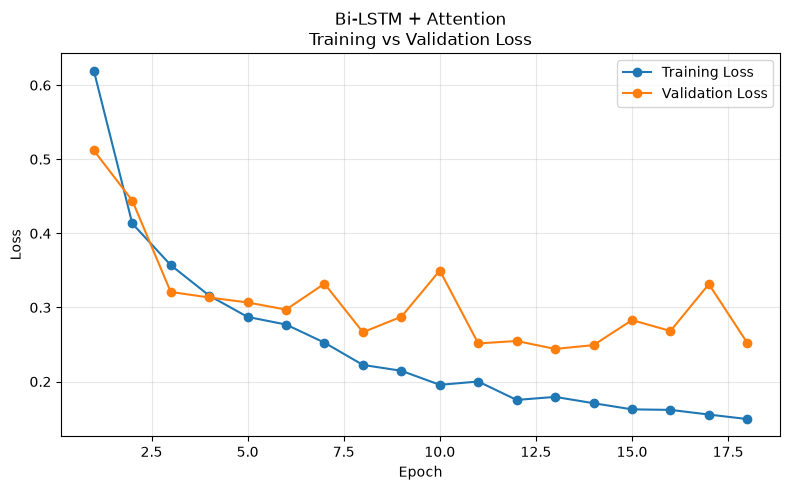

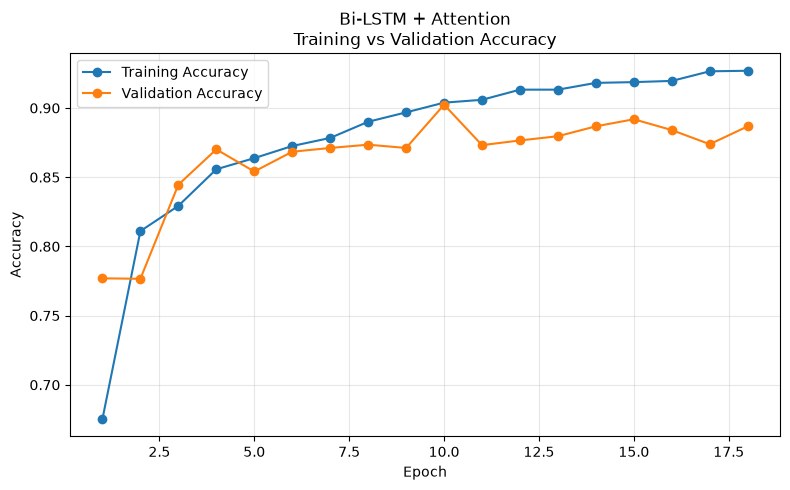


TEST RESULTS: Bi-LSTM + Attention

Test Loss: 0.3347
Accuracy : 0.8701
Precision: 0.9093
Recall   : 0.8701
F1 Score : 0.8822

----------------------------------------------------------------------
DETAILED CLASSIFICATION REPORT
----------------------------------------------------------------------
               precision    recall  f1-score   support

       Stable     0.8501    0.9602    0.9018       880
Moderate Risk     0.9646    0.8252    0.8895      1619
Critical Risk     0.2386    0.7500    0.3621        56

     accuracy                         0.8701      2555
    macro avg     0.6845    0.8451    0.7178      2555
 weighted avg     0.9093    0.8701    0.8822      2555


----------------------------------------------------------------------
CONFUSION MATRIX: Bi-LSTM + Attention
----------------------------------------------------------------------
[[ 845   35    0]
 [ 149 1336  134]
 [   0   14   42]]


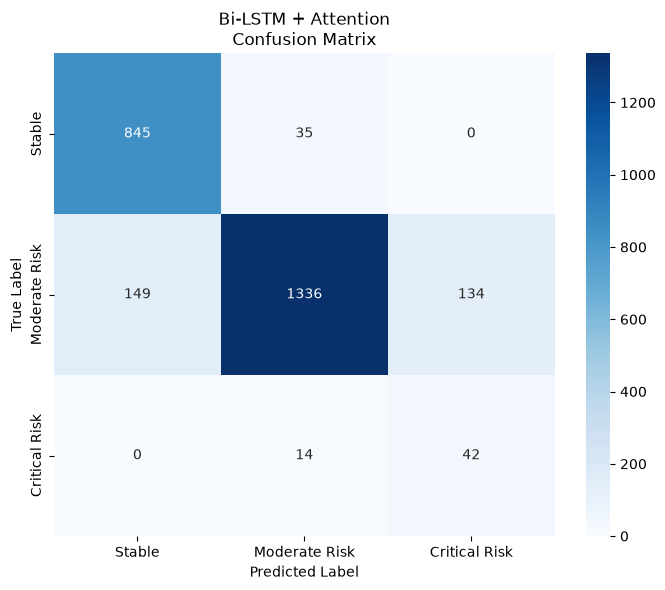




TRAINING: GRU + Attention
Epoch 01/30 | Train Loss: 0.7206 | Train Acc: 0.6202 | Val Loss: 0.6137 | Val Acc: 0.7028
Epoch 02/30 | Train Loss: 0.4719 | Train Acc: 0.7803 | Val Loss: 0.4900 | Val Acc: 0.7705
Epoch 03/30 | Train Loss: 0.3969 | Train Acc: 0.8218 | Val Loss: 0.3665 | Val Acc: 0.8446
Epoch 04/30 | Train Loss: 0.3475 | Train Acc: 0.8452 | Val Loss: 0.3615 | Val Acc: 0.8507
Epoch 05/30 | Train Loss: 0.3284 | Train Acc: 0.8513 | Val Loss: 0.3976 | Val Acc: 0.8800
Epoch 06/30 | Train Loss: 0.3162 | Train Acc: 0.8587 | Val Loss: 0.3624 | Val Acc: 0.8371
Epoch 07/30 | Train Loss: 0.2889 | Train Acc: 0.8740 | Val Loss: 0.4289 | Val Acc: 0.7844
Epoch 08/30 | Train Loss: 0.2714 | Train Acc: 0.8751 | Val Loss: 0.3920 | Val Acc: 0.8225
Epoch 09/30 | Train Loss: 0.2625 | Train Acc: 0.8820 | Val Loss: 0.3625 | Val Acc: 0.8589

Early stopping triggered.

Best model restored.
Training time: 35.68 seconds


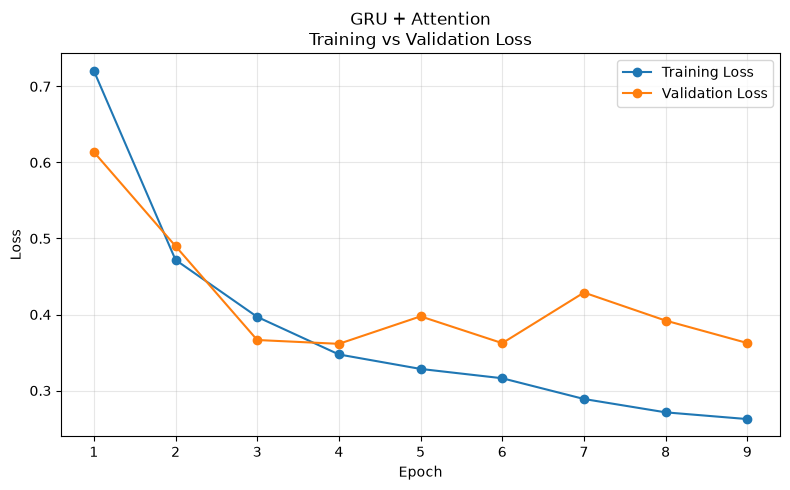

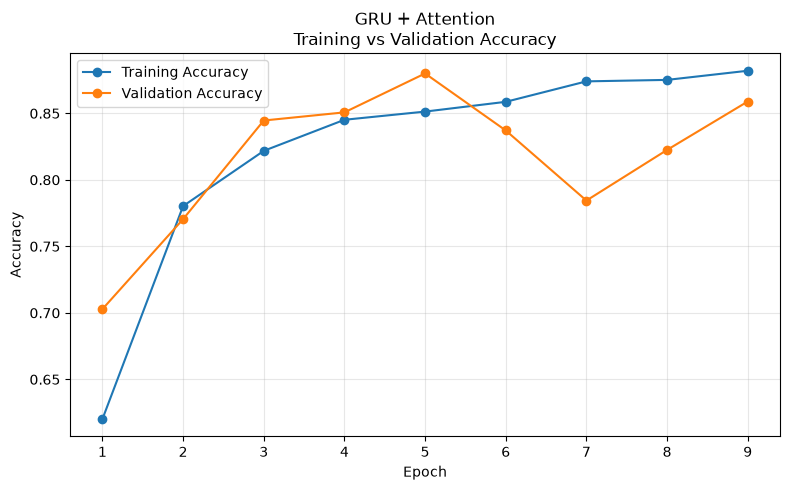


TEST RESULTS: GRU + Attention

Test Loss: 0.4975
Accuracy : 0.8317
Precision: 0.8736
Recall   : 0.8317
F1 Score : 0.8398

----------------------------------------------------------------------
DETAILED CLASSIFICATION REPORT
----------------------------------------------------------------------
               precision    recall  f1-score   support

       Stable     0.7544    0.9636    0.8463       880
Moderate Risk     0.9598    0.7671    0.8527      1619
Critical Risk     0.2555    0.6250    0.3627        56

     accuracy                         0.8317      2555
    macro avg     0.6566    0.7853    0.6872      2555
 weighted avg     0.8736    0.8317    0.8398      2555


----------------------------------------------------------------------
CONFUSION MATRIX: GRU + Attention
----------------------------------------------------------------------
[[ 848   32    0]
 [ 275 1242  102]
 [   1   20   35]]


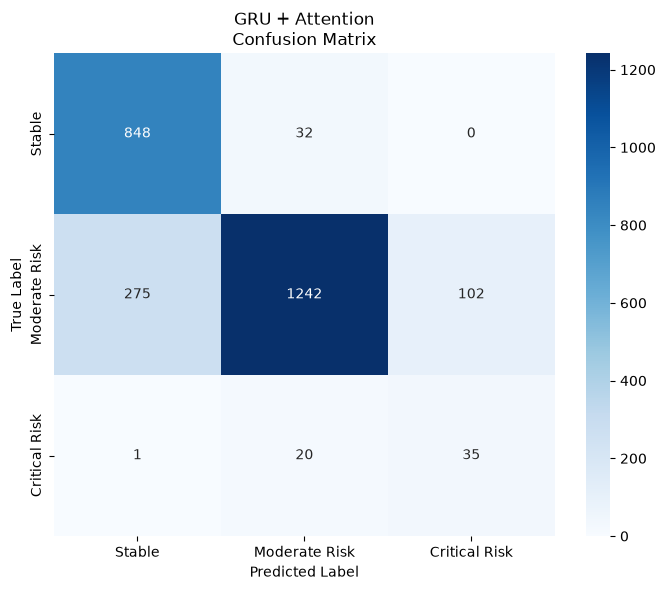




TRAINING: 1D CNN
Epoch 01/30 | Train Loss: 0.6139 | Train Acc: 0.6847 | Val Loss: 0.5518 | Val Acc: 0.7790
Epoch 02/30 | Train Loss: 0.5103 | Train Acc: 0.7557 | Val Loss: 0.5159 | Val Acc: 0.7841
Epoch 03/30 | Train Loss: 0.4453 | Train Acc: 0.7797 | Val Loss: 0.4807 | Val Acc: 0.7956
Epoch 04/30 | Train Loss: 0.4150 | Train Acc: 0.7944 | Val Loss: 0.5107 | Val Acc: 0.8143
Epoch 05/30 | Train Loss: 0.3752 | Train Acc: 0.8130 | Val Loss: 0.4665 | Val Acc: 0.8191
Epoch 06/30 | Train Loss: 0.3565 | Train Acc: 0.8253 | Val Loss: 0.4234 | Val Acc: 0.8327
Epoch 07/30 | Train Loss: 0.3332 | Train Acc: 0.8330 | Val Loss: 0.3987 | Val Acc: 0.8456
Epoch 08/30 | Train Loss: 0.3226 | Train Acc: 0.8377 | Val Loss: 0.4455 | Val Acc: 0.8273
Epoch 09/30 | Train Loss: 0.3197 | Train Acc: 0.8437 | Val Loss: 0.5147 | Val Acc: 0.8341
Epoch 10/30 | Train Loss: 0.3016 | Train Acc: 0.8526 | Val Loss: 0.4736 | Val Acc: 0.8409
Epoch 11/30 | Train Loss: 0.2844 | Train Acc: 0.8599 | Val Loss: 0.3816 | Val Ac

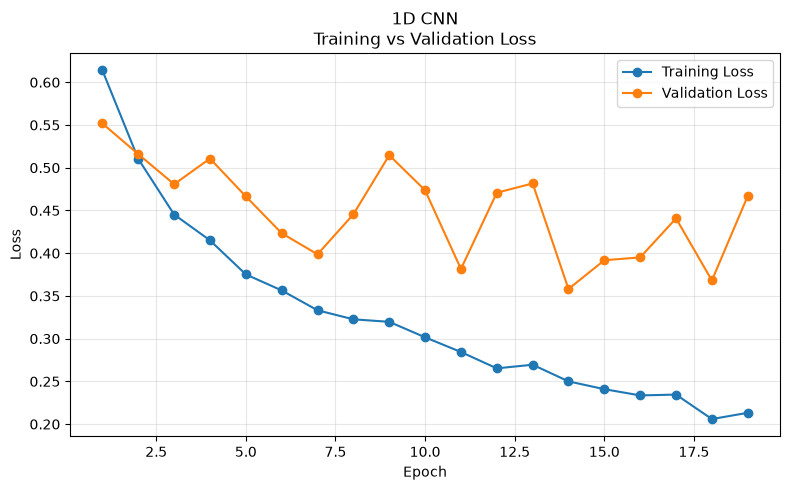

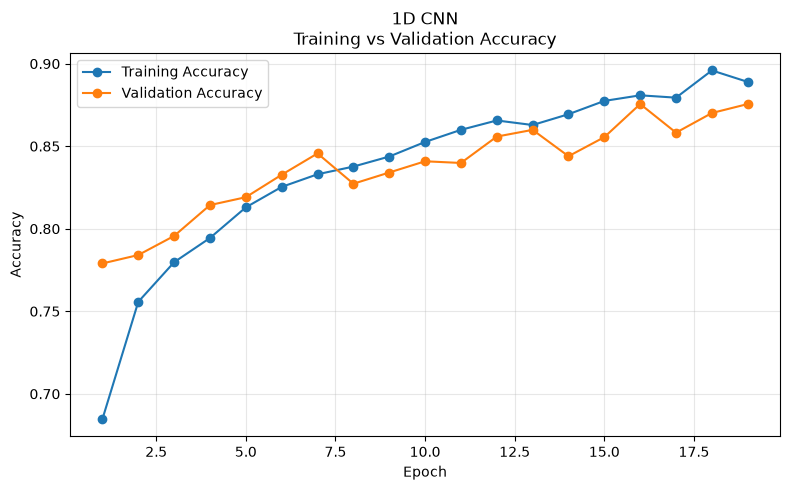


TEST RESULTS: 1D CNN

Test Loss: 0.4821
Accuracy : 0.8023
Precision: 0.8475
Recall   : 0.8023
F1 Score : 0.8183

----------------------------------------------------------------------
DETAILED CLASSIFICATION REPORT
----------------------------------------------------------------------
               precision    recall  f1-score   support

       Stable     0.7935    0.8602    0.8255       880
Moderate Risk     0.8996    0.7746    0.8324      1619
Critical Risk     0.1884    0.6964    0.2966        56

     accuracy                         0.8023      2555
    macro avg     0.6272    0.7771    0.6515      2555
 weighted avg     0.8475    0.8023    0.8183      2555


----------------------------------------------------------------------
CONFUSION MATRIX: 1D CNN
----------------------------------------------------------------------
[[ 757  123    0]
 [ 197 1254  168]
 [   0   17   39]]


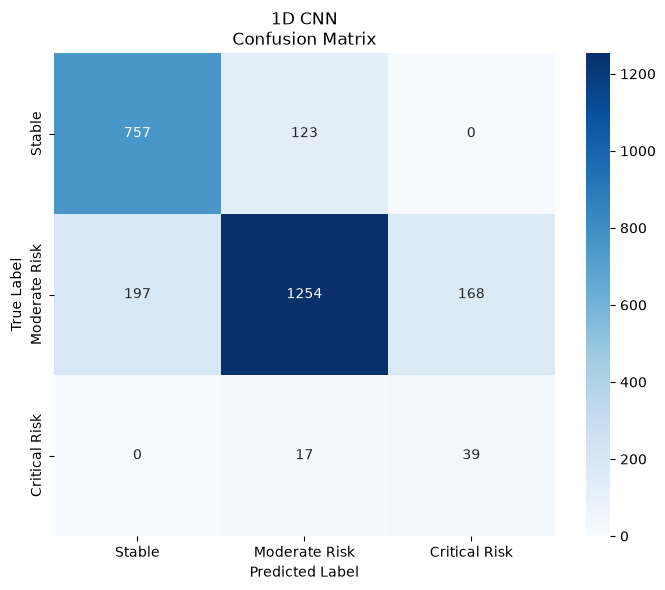

In [46]:
# ============================================================
# STEP 40: TRAIN ALL THREE MODELS
# ============================================================

results = {}

histories = {}

training_times = {}


for model_name in models:

    model = models[model_name]


    # Train

    model, history, training_time = (

        train_model(

            model,

            model_name

        )

    )


    # Save model back

    models[model_name] = model


    # Save history

    histories[model_name] = history


    # Save time

    training_times[model_name] = (
        training_time
    )


    # Plot curves

    plot_training_curves(

        history,

        model_name

    )


    # Test

    model_results = test_model(

        model,

        model_name

    )


    results[model_name] = (
        model_results
    )


    # Confusion matrix

    plot_confusion_matrix(

        model_results["y_true"],

        model_results["y_pred"],

        model_name

    )


In [47]:
# ============================================================
# SAVE TRAINED BI-LSTM + ATTENTION MODEL
# ============================================================

import os
import torch

# Make sure model folder exists
os.makedirs("model", exist_ok=True)

# Get the trained Bi-LSTM + Attention model
bilstm_model = models["Bi-LSTM + Attention"]

# Save trained weights
torch.save(
    bilstm_model.state_dict(),
    "model/bilstm_attention_phase1.pth"
)

# Verify
print("Bi-LSTM model saved successfully!")
print("Path: model/bilstm_attention_phase1.pth")
print("Parameters:", sum(p.numel() for p in bilstm_model.parameters()))

Bi-LSTM model saved successfully!
Path: model/bilstm_attention_phase1.pth
Parameters: 152964


In [48]:
# ============================================================
# STEP 41: MODEL COMPARISON TABLE
# ============================================================

print("\n\n")

print("=" * 90)

print("FINAL MODEL COMPARISON")

print("=" * 90)


comparison_rows = []


for model_name in models:

    model = models[model_name]

    result = results[model_name]


    comparison_rows.append({

        "Model": model_name,

        "Accuracy":
            result["accuracy"],

        "Precision":
            result["precision"],

        "Recall":
            result["recall"],

        "F1 Score":
            result["f1"],

        "Parameters":
            count_parameters(model),

        "Training Time (sec)":
            training_times[model_name]

    })


comparison_df = pd.DataFrame(
    comparison_rows
)


display(
    comparison_df
)




FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,Parameters,Training Time (sec)
0,Bi-LSTM + Attention,0.870059,0.909266,0.870059,0.882169,152964,152.357681
1,GRU + Attention,0.831703,0.873644,0.831703,0.839777,47364,35.680087
2,1D CNN,0.802348,0.847450,0.802348,0.818281,34755,30.068861


In [49]:
# ============================================================
# STEP 42: ROUNDED COMPARISON TABLE
# ============================================================

print("\n" + "=" * 90)

print("ROUNDED COMPARISON TABLE")

print("=" * 90)


comparison_display = comparison_df.copy()


comparison_display[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ]
] = comparison_display[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ]
].round(4)


comparison_display[
    "Training Time (sec)"
] = comparison_display[
    "Training Time (sec)"
].round(2)


display(
    comparison_display
)




ROUNDED COMPARISON TABLE


,Model,Accuracy,Precision,Recall,F1 Score,Parameters,Training Time (sec)
0,Bi-LSTM + Attention,0.8701,0.9093,0.8701,0.8822,152964,152.36
1,GRU + Attention,0.8317,0.8736,0.8317,0.8398,47364,35.68
2,1D CNN,0.8023,0.8475,0.8023,0.8183,34755,30.07



MODEL PERFORMANCE COMPARISON


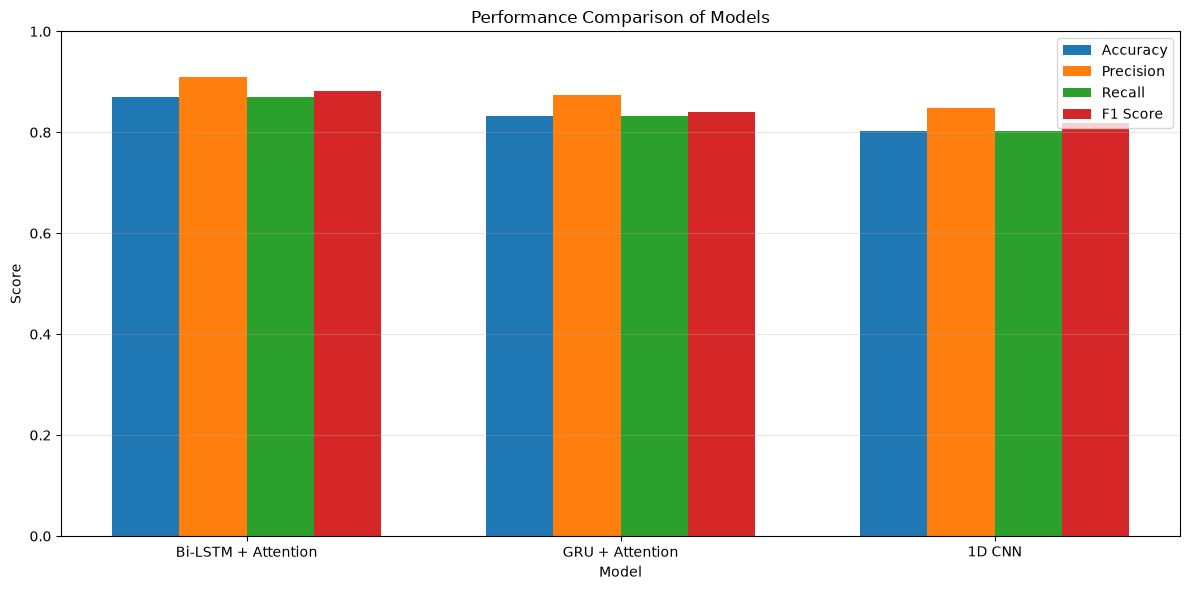

In [50]:
# ============================================================
# STEP 43: PERFORMANCE COMPARISON GRAPH
# ============================================================

print("\n" + "=" * 70)

print("MODEL PERFORMANCE COMPARISON")

print("=" * 70)


metrics = [

    "Accuracy",

    "Precision",

    "Recall",

    "F1 Score"

]


x = np.arange(
    len(models)
)


width = 0.18


plt.figure(
    figsize=(12, 6)
)


for i, metric in enumerate(metrics):

    values = comparison_df[
        metric
    ].values


    plt.bar(

        x
        + (i - 1.5)
        * width,

        values,

        width,

        label=metric

    )


plt.xticks(

    x,

    comparison_df["Model"]

)


plt.ylabel("Score")

plt.xlabel("Model")

plt.title(
    "Performance Comparison of Models"
)


plt.ylim(
    0,
    1
)


plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)


plt.tight_layout()

plt.show()




TRAINING TIME COMPARISON


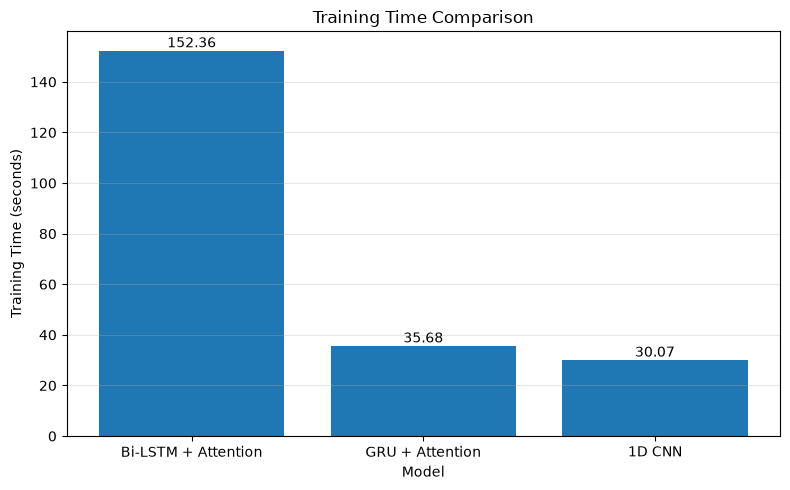

In [51]:
# ============================================================
# STEP 44: TRAINING TIME COMPARISON
# ============================================================

print("\n" + "=" * 70)

print("TRAINING TIME COMPARISON")

print("=" * 70)


plt.figure(
    figsize=(8, 5)
)


bars = plt.bar(

    comparison_df["Model"],

    comparison_df[
        "Training Time (sec)"
    ]

)


plt.xlabel("Model")

plt.ylabel(
    "Training Time (seconds)"
)

plt.title(
    "Training Time Comparison"
)


plt.grid(
    axis="y",
    alpha=0.3
)


for bar, value in zip(

    bars,

    comparison_df[
        "Training Time (sec)"
    ]

):

    plt.text(

        bar.get_x()
        + bar.get_width() / 2,

        bar.get_height(),

        f"{value:.2f}",

        ha="center",

        va="bottom"

    )


plt.tight_layout()

plt.show()




MODEL PARAMETER COMPARISON


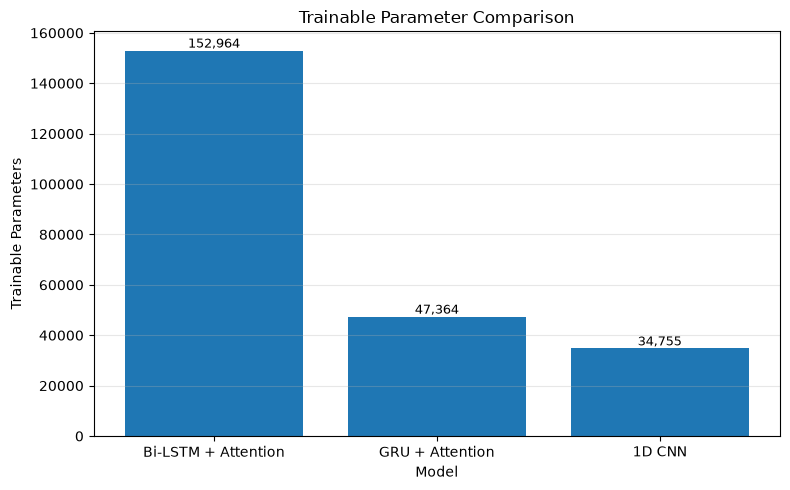

In [52]:

# ============================================================
# STEP 45: PARAMETER COUNT COMPARISON
# ============================================================

print("\n" + "=" * 70)

print("MODEL PARAMETER COMPARISON")

print("=" * 70)


plt.figure(
    figsize=(8, 5)
)


bars = plt.bar(

    comparison_df["Model"],

    comparison_df["Parameters"]

)


plt.xlabel("Model")

plt.ylabel(
    "Trainable Parameters"
)

plt.title(
    "Trainable Parameter Comparison"
)


plt.grid(
    axis="y",
    alpha=0.3
)


for bar, value in zip(

    bars,

    comparison_df[
        "Parameters"
    ]

):

    plt.text(

        bar.get_x()
        + bar.get_width() / 2,

        bar.get_height(),

        f"{value:,}",

        ha="center",

        va="bottom",

        fontsize=9

    )


plt.tight_layout()

plt.show()


In [53]:
# ============================================================
# STEP 46: CLASS-WISE F1 COMPARISON
# ============================================================

print("\n" + "=" * 70)

print("CLASS-WISE F1 SCORE COMPARISON")

print("=" * 70)


class_f1_results = {}


for model_name in models:

    y_true = results[
        model_name
    ]["y_true"]

    y_pred = results[
        model_name
    ]["y_pred"]


    report = classification_report(

        y_true,

        y_pred,

        target_names=CLASS_NAMES,

        output_dict=True,

        zero_division=0

    )


    class_f1_results[model_name] = [

        report["Stable"]["f1-score"],

        report["Moderate Risk"]["f1-score"],

        report["Critical Risk"]["f1-score"]

    ]


class_f1_df = pd.DataFrame(

    class_f1_results,

    index=CLASS_NAMES

)


display(
    class_f1_df
)



CLASS-WISE F1 SCORE COMPARISON


,Bi-LSTM + Attention,GRU + Attention,1D CNN
Stable,0.901814,0.846307,0.825518
Moderate Risk,0.889481,0.852729,0.832393
Critical Risk,0.362069,0.362694,0.296578


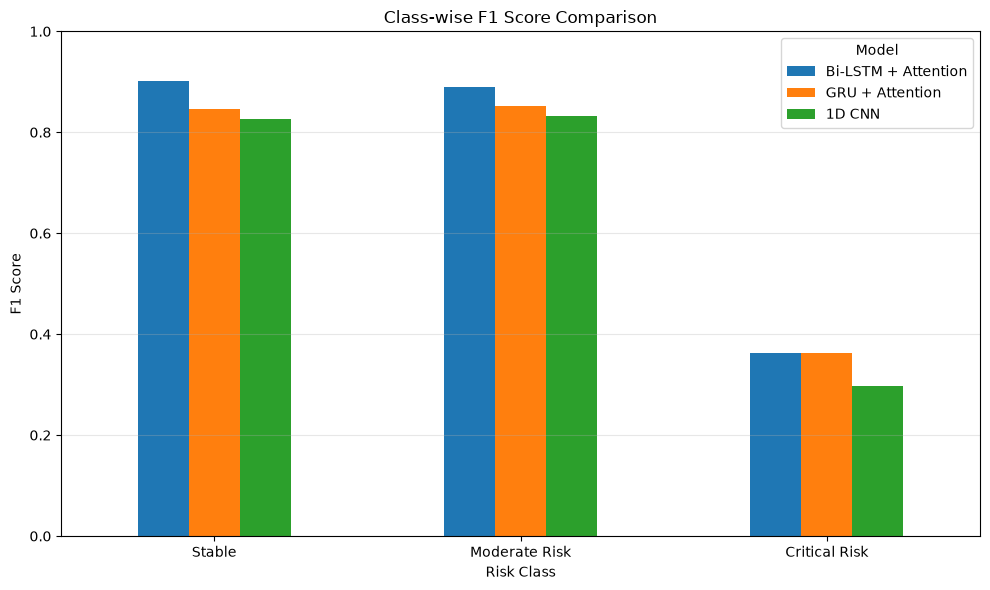

In [54]:
# ------------------------------------------------------------
# Graph
# ------------------------------------------------------------

class_f1_df.plot(

    kind="bar",

    figsize=(10, 6)

)


plt.xlabel("Risk Class")

plt.ylabel("F1 Score")

plt.title(
    "Class-wise F1 Score Comparison"
)

plt.ylim(
    0,
    1
)

plt.xticks(
    rotation=0
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.legend(
    title="Model"
)

plt.tight_layout()

plt.show()


In [55]:
# ============================================================
# STEP 47: CRITICAL RISK COMPARISON
# ============================================================

print("\n" + "=" * 70)

print("CRITICAL RISK CLASS PERFORMANCE")

print("=" * 70)


critical_rows = []


for model_name in models:

    y_true = results[
        model_name
    ]["y_true"]

    y_pred = results[
        model_name
    ]["y_pred"]


    report = classification_report(

        y_true,

        y_pred,

        target_names=CLASS_NAMES,

        output_dict=True,

        zero_division=0

    )


    critical_rows.append({

        "Model": model_name,

        "Critical Precision":
            report[
                "Critical Risk"
            ]["precision"],

        "Critical Recall":
            report[
                "Critical Risk"
            ]["recall"],

        "Critical F1":
            report[
                "Critical Risk"
            ]["f1-score"],

        "Critical Support":
            report[
                "Critical Risk"
            ]["support"]

    })


critical_df = pd.DataFrame(
    critical_rows
)


display(
    critical_df
)


CRITICAL RISK CLASS PERFORMANCE


,Model,Critical Precision,Critical Recall,Critical F1,Critical Support
0,Bi-LSTM + Attention,0.238636,0.750000,0.362069,56.0
1,GRU + Attention,0.255474,0.625000,0.362694,56.0
2,1D CNN,0.188406,0.696429,0.296578,56.0



ATTENTION VISUALIZATION
True class: Moderate Risk
Predicted class: Moderate Risk

Attention weights:
Timestep 01: 0.0004
Timestep 02: 0.0013
Timestep 03: 0.0046
Timestep 04: 0.0132
Timestep 05: 0.0275
Timestep 06: 0.0485
Timestep 07: 0.0778
Timestep 08: 0.1308
Timestep 09: 0.2730
Timestep 10: 0.4229


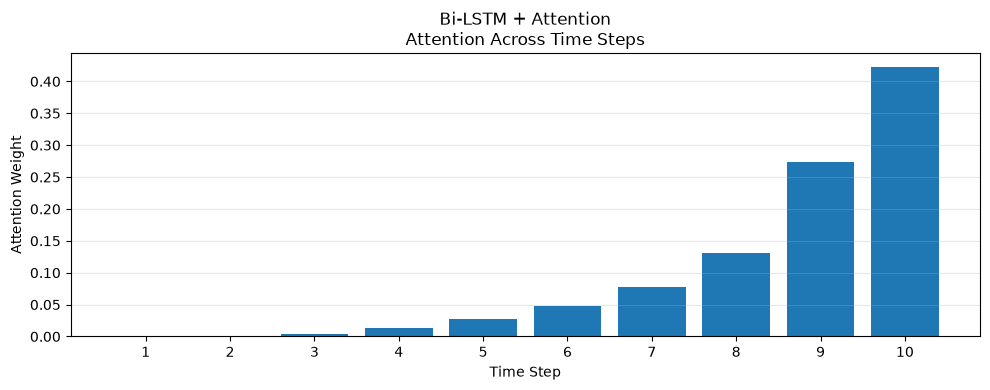

True class: Moderate Risk
Predicted class: Moderate Risk

Attention weights:
Timestep 01: 0.0000
Timestep 02: 0.0000
Timestep 03: 0.0000
Timestep 04: 0.0000
Timestep 05: 0.0000
Timestep 06: 0.0000
Timestep 07: 0.0001
Timestep 08: 0.0059
Timestep 09: 0.2598
Timestep 10: 0.7342


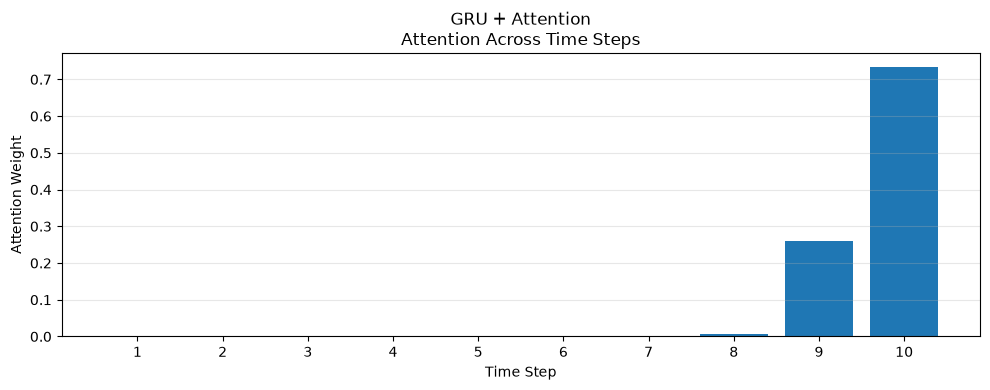

In [56]:
# ============================================================
# STEP 48: ATTENTION VISUALIZATION
# ============================================================

print("\n" + "=" * 70)

print("ATTENTION VISUALIZATION")

print("=" * 70)


def plot_attention(

    model,

    model_name,

    sample_index=0

):

    if "Attention" not in model_name:

        print(
            f"{model_name} does not use attention."
        )

        return


    model.eval()


    sample = X_test_tensor[
        sample_index
    ].unsqueeze(0).to(device)


    with torch.no_grad():

        output, attention_weights = (

            model(

                sample,

                return_attention=True

            )

        )


    attention_weights = (

        attention_weights

        .squeeze()

        .cpu()

        .numpy()

    )


    predicted_class = (

        torch.argmax(
            output,
            dim=1
        )

        .item()

    )


    true_class = (

        y_test[
            sample_index
        ]

    )


    print(
        "True class:",
        CLASS_NAMES[true_class]
    )

    print(
        "Predicted class:",
        CLASS_NAMES[predicted_class]
    )


    print("\nAttention weights:")

    for timestep, weight in enumerate(
        attention_weights,
        start=1
    ):

        print(

            f"Timestep {timestep:02d}: "
            f"{weight:.4f}"

        )


    plt.figure(
        figsize=(10, 4)
    )


    plt.bar(

        range(
            1,
            SEQUENCE_LENGTH + 1
        ),

        attention_weights

    )


    plt.xlabel(
        "Time Step"
    )

    plt.ylabel(
        "Attention Weight"
    )

    plt.title(

        f"{model_name}\n"
        "Attention Across Time Steps"

    )


    plt.xticks(
        range(
            1,
            SEQUENCE_LENGTH + 1
        )
    )


    plt.grid(
        axis="y",
        alpha=0.3
    )


    plt.tight_layout()

    plt.show()


# Bi-LSTM attention

plot_attention(

    models[
        "Bi-LSTM + Attention"
    ],

    "Bi-LSTM + Attention"

)


# GRU attention

plot_attention(

    models[
        "GRU + Attention"
    ],

    "GRU + Attention"

)

In [57]:
# ============================================================
# STEP 49: FINAL SUMMARY
# ============================================================

print("\n\n")

print("=" * 90)

print("FINAL EXPERIMENT SUMMARY")

print("=" * 90)


print("\nDataset:")

print(
    "MIMIC-IV Demo ICU time-series data"
)


print(
    "Patients:",
    len(unique_subjects)
)


print(
    "Sequences:",
    len(X)
)


print(
    "Sequence length:",
    SEQUENCE_LENGTH
)


print(
    "Features:",
    INPUT_SIZE
)


print(
    "Training patients:",
    len(train_subjects)
)


print(
    "Validation patients:",
    len(val_subjects)
)


print(
    "Testing patients:",
    len(test_subjects)
)


print("\nModels evaluated:")

for model_name in models:

    print(
        " -",
        model_name
    )


print("\n" + "-" * 90)

print("FINAL RESULTS")

print("-" * 90)


display(
    comparison_display
)


print("\nExperiment completed successfully!")





FINAL EXPERIMENT SUMMARY

Dataset:
MIMIC-IV Demo ICU time-series data
Patients: 100
Sequences: 18167
Sequence length: 10
Features: 6
Training patients: 70
Validation patients: 15
Testing patients: 15

Models evaluated:
 - Bi-LSTM + Attention
 - GRU + Attention
 - 1D CNN

------------------------------------------------------------------------------------------
FINAL RESULTS
------------------------------------------------------------------------------------------


,Model,Accuracy,Precision,Recall,F1 Score,Parameters,Training Time (sec)
0,Bi-LSTM + Attention,0.8701,0.9093,0.8701,0.8822,152964,152.36
1,GRU + Attention,0.8317,0.8736,0.8317,0.8398,47364,35.68
2,1D CNN,0.8023,0.8475,0.8023,0.8183,34755,30.07



Experiment completed successfully!


In [58]:
# ============================================================
# STEP 50: SAVE RESULTS
# ============================================================

print("\n" + "=" * 70)

print("SAVING RESULTS")

print("=" * 70)


comparison_df.to_csv(

    "model_comparison_results.csv",

    index=False

)


critical_df.to_csv(

    "critical_risk_results.csv",

    index=False

)


class_f1_df.to_csv(

    "class_wise_f1_results.csv"

)


print(
    "Saved:"
)

print(
    " - model_comparison_results.csv"
)

print(
    " - critical_risk_results.csv"
)

print(
    " - class_wise_f1_results.csv"
)


print("\nAll experiments completed!")


SAVING RESULTS
Saved:
 - model_comparison_results.csv
 - critical_risk_results.csv
 - class_wise_f1_results.csv

All experiments completed!
